In [ ]:
!pip install -q \
    requests python-dotenv \
    beautifulsoup4 lxml \
    pypdf \
    langchain langchain-openai \
    langchain-community langchain-experimental \
    langchain-text-splitters \
    sentence-transformers \
    chromadb \
    networkx

In [ ]:
from pathlib import Path
import os

ENVIRONMENT = "colab"
LLM_PROVIDER = "aitunnel"

GROBID_URL = "https://ever-womens-leading-kai.trycloudflare.com"

CHUNK_SIZE = 800
CHUNK_OVERLAP = 100
TOP_K_VECTOR = 5
TOP_K_GRAPH = 5

EMBEDDING_MODEL = "intfloat/multilingual-e5-small"
LLM_MODEL = "llama-3.3-70b-instruct"          # модель на AITunnel
AITUNNEL_BASE_URL = "https://api.aitunnel.ru/v1"

from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path("/content/drive/MyDrive/vkr")
PAPERS_DIR = PROJECT_ROOT / "papers"
DATA_DIR = PROJECT_ROOT / "data"
CHROMA_DIR = DATA_DIR / "chroma"
GRAPH_PATH = DATA_DIR / "graph.pkl"
INDEXING_LOG_PATH = DATA_DIR / "indexing_log.csv"
NOTES_PATH = PROJECT_ROOT / "notes.md"
JUDGE_PATH = "/content/drive/MyDrive/vkr/data/judge_scores.json"

from google.colab import userdata
try:
    os.environ["AITUNNEL_API_KEY"] = userdata.get("AITUNNEL_API_KEY")
except Exception as e:
    raise RuntimeError(
        "AITUNNEL_API_KEY не найден в Colab Secrets."
    ) from e


def get_llm(temperature: float = 0.0):
    if LLM_PROVIDER == "aitunnel":
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(
            model=LLM_MODEL,
            temperature=temperature,
            base_url=AITUNNEL_BASE_URL,
            api_key=os.environ["AITUNNEL_API_KEY"],
        )
    raise ValueError(f"Unknown LLM_PROVIDER: {LLM_PROVIDER}")

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"LLM_PROVIDER = {LLM_PROVIDER}, модель = {LLM_MODEL}")

llm = get_llm()
response = llm.invoke("Ответь одним словом: pong")
print(f"\nОтвет LLM на тестовый запрос: {response.content}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_ROOT = /content/drive/MyDrive/vkr
LLM_PROVIDER = aitunnel, модель = llama-3.3-70b-instruct

Ответ LLM на тестовый запрос: Пинг


In [ ]:
'''import networkx as nx, pickle
# Пересоздаём граф с нуля - старый в graph.pkl засорён дублями связей
graph = nx.MultiDiGraph()
with open(GRAPH_PATH, "wb") as f:
    pickle.dump(graph, f)
print("Граф очищен:", graph.number_of_nodes(), "узлов,", graph.number_of_edges(), "связей") '''

In [ ]:
# парсинг pdf через GROBID и разбор TEI в dict

import requests
import time
from bs4 import BeautifulSoup

# PDF -> GROBID
def parse_pdf_with_grobid(pdf_path, grobid_url=GROBID_URL, max_retries=3):
    endpoint = f"{grobid_url}/api/processFulltextDocument"
    last_error = None

    for attempt in range(max_retries):
        try:
            with open(pdf_path, "rb") as f:
                response = requests.post(
                    endpoint,
                    files={"input": f},
                    timeout=180,
                )
            # 200 и 206 оба считаем успехом, если тело похоже на TEI
            if response.status_code in (200, 206):
                text = response.text
                if "<TEI" in text and "<body" in text:
                    return text
                elif "Preparing Space" in text or "<!DOCTYPE html>" in text[:200]:
                    last_error = (
                        "GROBID Space спит или перегружен (HF возвращает HTML-заглушку). "
                        "Попробуй через несколько минут или смени GROBID_URL на резервный Space."
                    )
                    print(last_error)
                else:
                    last_error = f"Статус {response.status_code}, но тело не содержит TEI (длина {len(text)})"
                    print(last_error)

        except requests.exceptions.RequestException as e:
            last_error = f"Ошибка сети: {e}"
            print(f"{last_error}, попытка {attempt + 1}/{max_retries}")

        # экспоненциальная задержка 2 4 8 с
        if attempt < max_retries - 1:
            time.sleep(2 ** (attempt + 1))

    raise RuntimeError(f"Не удалось получить TEI от GROBID после {max_retries} попыток. Последняя ошибка: {last_error}")


# TEI -> dict
    """
      title: str
      authors: list[str]
      keywords: list[str]
      parts: list[dict] - каждая часть имеет поля 'heading' и 'text'

    "Часть статьи" в терминологии ТЗ - это заголовок любого уровня
    и весь текст до следующего заголовка. Иерархия не сохраняется,
    только порядок следования (это важно для previous_part связей в графе)
    """
def tei_to_dict(tei_xml):

    soup = BeautifulSoup(tei_xml, "lxml-xml")

    title_tag = soup.find("titleStmt")
    title = ""
    if title_tag and title_tag.find("title"):
        title = title_tag.find("title").get_text(strip=True)

    authors = []
    source_desc = soup.find("sourceDesc")
    if source_desc:
        for author_tag in source_desc.find_all("author"):
            pers_name = author_tag.find("persName")
            if pers_name:
                forenames = [fn.get_text(strip=True) for fn in pers_name.find_all("forename")]
                surnames = [sn.get_text(strip=True) for sn in pers_name.find_all("surname")]
                full_name = " ".join(forenames + surnames).strip()
                if full_name:
                    authors.append(full_name)

    keywords = []
    keywords_tag = soup.find("keywords")
    if keywords_tag:
        terms = keywords_tag.find_all("term")
        if terms:
            keywords = [t.get_text(strip=True) for t in terms if t.get_text(strip=True)]
        else:
            # Fallback: текст через запятую или точку с запятой
            raw = keywords_tag.get_text(strip=True)
            if raw:
                keywords = [k.strip() for k in raw.replace(";", ",").split(",") if k.strip()]

    # тело - <body>, внутри него <div> для каждого раздела
    # в каждом <div> есть <head> (заголовок) и несколько <p>
    # плюс добавляем abstract как первую часть, если он есть
    parts = []

    abstract_tag = soup.find("abstract")
    if abstract_tag:
        abstract_text = " ".join(p.get_text(" ", strip=True) for p in abstract_tag.find_all("p"))
        if abstract_text:
            parts.append({"heading": "Abstract", "text": abstract_text})

    body = soup.find("body")
    if body:
        for div in body.find_all("div", recursive=False):
            head_tag = div.find("head")
            heading = head_tag.get_text(strip=True) if head_tag else "(без заголовка)"

            # собираем все параграфы
            paragraphs = [p.get_text(" ", strip=True) for p in div.find_all("p")]
            text = "\n\n".join(p for p in paragraphs if p)

            if text:  # скип пустых разделов
                parts.append({"heading": heading, "text": text})

    return {
        "title": title,
        "authors": authors,
        "keywords": keywords,
        "parts": parts,
    }


# тест на одну пдф, берём первый PDF из папки papers/ и гоняем его через всю цепочку
pdf_files = sorted(PAPERS_DIR.glob("*.pdf"))
if not pdf_files:
    raise FileNotFoundError(f"В {PAPERS_DIR} нет PDF-файлов. Положи хотя бы один.")

test_pdf = pdf_files[0]
print(f"Тестовый файл: {test_pdf.name}")
print("Отправляю в GROBID (первый запрос может идти до 2 минут)...")

tei = parse_pdf_with_grobid(test_pdf)
print(f"TEI получен, длина: {len(tei)} символов")

article = tei_to_dict(tei)

print(f"\nЗаголовок: {article['title']}")
print(f"Авторов: {len(article['authors'])}")
for a in article['authors'][:5]:
    print(f"  - {a}")
print(f"Ключевых слов: {len(article['keywords'])}")
if article['keywords']:
    print(f"  {article['keywords']}")
print(f"Частей: {len(article['parts'])}")
for i, part in enumerate(article['parts']):
    print(f"  [{i}] {part['heading']} - {len(part['text'])} симв.")

In [ ]:
# чанкинг и индексация в ChromaDB

import chromadb
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import RecursiveCharacterTextSplitter

# ленивая загрузка эммбедера
_embedder = None

def get_embedder():
    global _embedder
    if _embedder is None:
        print(f"Загружаю модель {EMBEDDING_MODEL} (первый раз ~2 мин)...")
        _embedder = SentenceTransformer(EMBEDDING_MODEL)
        print("Модель загружена")
    return _embedder


# чанкинг статьи
def chunk_article(article, source_filename):
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=CHUNK_SIZE,
        chunk_overlap=CHUNK_OVERLAP,
        separators=["\n\n", "\n", ". ", " ", ""],
    )

    chunks = []
    for part_idx, part in enumerate(article["parts"]):
        part_chunks = splitter.split_text(part["text"])
        for chunk_idx, chunk_text in enumerate(part_chunks):
            chunk_id = f"{source_filename}::part{part_idx}::chunk{chunk_idx}"
            chunks.append({
                "text": chunk_text,
                "chunk_id": chunk_id,
                "metadata": {
                    "source": source_filename,
                    "title": article["title"],
                    "part_index": part_idx,
                    "part_heading": part["heading"],
                    "chunk_index": chunk_idx,
                },
            })
    return chunks


# подключение к ChromaDB
# PersistentClient хранит данные на диске, живет больше одной сессии
chroma_client = chromadb.PersistentClient(path=str(CHROMA_DIR))

# одна коллекция на весь корпус статей
COLLECTION_NAME = "articles"

collection = chroma_client.get_or_create_collection(
    name=COLLECTION_NAME,
    metadata={"hnsw:space": "cosine"},  # косинусная метрика, как в ТЗ
)
print(f"Коллекция '{COLLECTION_NAME}' готова, документов в ней: {collection.count()}")


# индексация
def index_article(article, source_filename):
    chunks = chunk_article(article, source_filename)
    if not chunks:
        print(f"Статья {source_filename} не дала ни одного чанка")
        return 0

    embedder = get_embedder()
    texts_for_embedding = [f"passage: {c['text']}" for c in chunks] # добавбляем passage для лучшей индексации
    embeddings = embedder.encode(
        texts_for_embedding,
        show_progress_bar=True,
        normalize_embeddings=True,  # нормализуем для косинусной метрики
    ).tolist()

    collection.upsert(
        ids=[c["chunk_id"] for c in chunks],
        embeddings=embeddings,
        documents=[c["text"] for c in chunks],
        metadatas=[c["metadata"] for c in chunks],
    )
    return len(chunks)


# поиск в ChromaDB
def vector_search(query, top_k=TOP_K_VECTOR):
    embedder = get_embedder()
    query_embedding = embedder.encode(
        f"query: {query}",  # query для лучшего поиска
        normalize_embeddings=True,
    ).tolist()

    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=top_k,
    )

    # распаковка в удобный формат
    found = []
    for i in range(len(results["ids"][0])):
        found.append({
            "text": results["documents"][0][i],
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i],
        })
    return found


# тест на article

n_added = index_article(article, test_pdf.name)
print(f"\nПроиндексировано {n_added} чанков из {test_pdf.name}")
print(f"Всего в коллекции: {collection.count()} документов")

# тестовый поиск, проверяем, что эмбеддинги работают осмысленно
test_query = "How does the retriever component work?"
print(f"\nТестовый запрос: {test_query}")
print(f"Топ-{TOP_K_VECTOR} результатов:")
for i, res in enumerate(vector_search(test_query)):
    print(f"\n--- Результат {i+1} (distance={res['distance']:.4f}) ---")
    print(f"  Раздел: {res['metadata']['part_heading']}")
    print(f"  Текст: {res['text'][:200]}...")

In [ ]:
# извлечение сущностей через LLMGraphTransformer,
# построение NetworkX-графа, сохранение в pickle

import pickle
import time
import networkx as nx
from langchain_experimental.graph_transformers import LLMGraphTransformer
from langchain_core.documents import Document

if GRAPH_PATH.exists():
    with open(GRAPH_PATH, "rb") as f:
        graph = pickle.load(f)
    print(f"Граф загружен из {GRAPH_PATH}: {graph.number_of_nodes()} узлов, {graph.number_of_edges()} связей")
else:
    graph = nx.MultiDiGraph()
    print("Создан новый пустой граф")


llm_for_graph = get_llm(temperature=0.0)
graph_transformer = LLMGraphTransformer(llm=llm_for_graph)


# зовёт LLMGraphTransformer на тексте части статьи
# возвращает (nodes, relationships) - оба списка могут быть пустыми
# retry с экспоненциальной задержкой на случай rate limit от Groq
def extract_entities_with_retry(text, max_retries=3):
    doc = Document(page_content=text)
    for attempt in range(max_retries):
        try:
            graph_docs = graph_transformer.convert_to_graph_documents([doc])
            if graph_docs:
                return graph_docs[0].nodes, graph_docs[0].relationships
            return [], []
        except Exception as e:
            err_msg = str(e).lower()
            # rate limit от Groq - ждём дольше
            wait = 10 if "rate" in err_msg or "429" in err_msg else 2 ** (attempt + 1)
            print(f"  Ошибка извлечения сущностей: {e}. Жду {wait} сек, попытка {attempt + 1}/{max_retries}")
            time.sleep(wait)
    print(f"  Не удалось извлечь сущности после {max_retries} попыток, пропускаю")
    return [], []


# построение графа для одной статьи
def build_article_graph(article, source_filename, min_part_length=200):
    article_id = f"Article::{source_filename}"

    # очистка следов предыдущей индексации этой статьи, собираем узлы статьи: сам Article + все её ArticlePart + Summary
    nodes_to_remove = [article_id]
    for n, d in list(graph.nodes(data=True)):
        if d.get("source") == source_filename and d.get("type") in ("ArticlePart", "Summary"):
            nodes_to_remove.append(n)
    # удаление узла автоматически удаляет все инцидентные ему связи
    for n in nodes_to_remove:
        if graph.has_node(n):
            graph.remove_node(n)
    # Удаляем «осиротевшие» связи author_of/article_has_keyword,
    # которые вели к уже удалённому Article (на случай, если узел
    # Author/Keyword остался от других статей)
    # — они и так удалились вместе с article_id, отдельная чистка не нужна.

    # построение заново
    graph.add_node(article_id, type="Article", title=article["title"], source=source_filename)

    for author_name in article["authors"]:
        author_id = f"Author::{author_name}"
        graph.add_node(author_id, type="Author", name=author_name)
        graph.add_edge(author_id, article_id, type="author_of")

    for kw in article["keywords"]:
        kw_id = f"Keyword::{kw}"
        graph.add_node(kw_id, type="Keyword", name=kw)
        graph.add_edge(article_id, kw_id, type="article_has_keyword")

    prev_part_id = None
    for part_idx, part in enumerate(article["parts"]):
        part_id = f"ArticlePart::{source_filename}::{part_idx}"
        graph.add_node(
            part_id, type="ArticlePart",
            heading=part["heading"], part_index=part_idx, source=source_filename,
        )
        graph.add_edge(part_id, article_id, type="part_of")
        if prev_part_id is not None:
            graph.add_edge(part_id, prev_part_id, type="previous_part")
        prev_part_id = part_id

        if len(part["text"]) < min_part_length:
            continue
        print(f"  [{part_idx}] {part['heading'][:50]}: извлекаю сущности...")
        nodes, relationships = extract_entities_with_retry(part["text"])

        for node in nodes:
            entity_id = f"Entity::{str(node.id).lower().strip()}"
            if not graph.has_node(entity_id):
                graph.add_node(
                    entity_id, type="Entity",
                    name=str(node.id), entity_label=getattr(node, "type", "Unknown"),
                )
            graph.add_edge(entity_id, part_id, type="mentioned_in")

        for rel in relationships:
            src_id = f"Entity::{str(rel.source.id).lower().strip()}"
            tgt_id = f"Entity::{str(rel.target.id).lower().strip()}"
            if graph.has_node(src_id) and graph.has_node(tgt_id):
                graph.add_edge(
                    src_id, tgt_id, type="semantic_link",
                    label=rel.type, source_part=part_id,
                )

    print(f"Статья обработана. Граф: {graph.number_of_nodes()} узлов, {graph.number_of_edges()} связей")


def save_graph():
    with open(GRAPH_PATH, "wb") as f:
        pickle.dump(graph, f)
    print(f"Граф сохранён в {GRAPH_PATH}")


def graph_summary():
    from collections import Counter
    node_types = Counter(d.get("type", "?") for _, d in graph.nodes(data=True))
    edge_types = Counter(d.get("type", "?") for _, _, d in graph.edges(data=True))
    print(f"\nУзлов всего: {graph.number_of_nodes()}")
    for t, c in node_types.most_common():
        print(f"  {t}: {c}")
    print(f"Связей всего: {graph.number_of_edges()}")
    for t, c in edge_types.most_common():
        print(f"  {t}: {c}")


# тест
print(f"\nСтрою граф для статьи: {test_pdf.name}")
print("Это займёт 1-2 минуты (один LLM-запрос на каждую содержательную часть)\n")

build_article_graph(article, test_pdf.name)
save_graph()
graph_summary()

In [ ]:
# пересказы частей через ллм, узлы summary в графе
from langchain_core.prompts import ChatPromptTemplate

# промпт из приложения А научрука
SUMMARY_PROMPT = ChatPromptTemplate.from_template(
    "Write a concise summary of the following, return only the contents "
    "of the summary, do not translate text:\n\n{context}"
)

llm_for_summary = get_llm(temperature=0.0)
summary_chain = SUMMARY_PROMPT | llm_for_summary


# генерация одного пересказа с retry (rate limit groq)
def summarize_with_retry(text, max_retries=3):
    for attempt in range(max_retries):
        try:
            response = summary_chain.invoke({"context": text})
            return response.content.strip()
        except Exception as e:
            err_msg = str(e).lower()
            wait = 10 if "rate" in err_msg or "429" in err_msg else 2 ** (attempt + 1)
            print(f"  Ошибка пересказа: {e}. Жду {wait} сек, попытка {attempt + 1}/{max_retries}")
            time.sleep(wait)
    print(f"  Не удалось получить пересказ после {max_retries} попыток")
    return None


# добавление пересказов в граф
def add_summaries_to_graph(article, source_filename, min_part_length=200):
    article_id = f"Article::{source_filename}"
    if not graph.has_node(article_id):
        raise RuntimeError(
            f"В графе нет узла {article_id}. Сначала выполни предыдущий шаг для этой статьи."
        )

    summaries_added = 0
    for part_idx, part in enumerate(article["parts"]):
        if len(part["text"]) < min_part_length:
            continue

        part_id = f"ArticlePart::{source_filename}::{part_idx}"
        summary_id = f"Summary::{source_filename}::{part_idx}"


        if graph.has_node(summary_id):  # если пересказ для этой части уже есть в графе пропускаем
            continue

        print(f"  [{part_idx}] {part['heading'][:50]}: пересказываю...")
        summary_text = summarize_with_retry(part["text"])
        if summary_text is None:
            continue

        graph.add_node(
            summary_id,
            type="Summary",
            text=summary_text,
            source=source_filename,
            part_index=part_idx,
        )
        graph.add_edge(summary_id, article_id, type="summary_of")
        graph.add_edge(summary_id, part_id, type="summarizes_part")  # расширение: связь к конкретной части для удобства поиска
        summaries_added += 1

    print(f"\nДобавлено пересказов: {summaries_added}")
    return summaries_added


# тест
print(f"Генерирую пересказы для статьи: {test_pdf.name}")
print("Это займёт 1.5-2 минуты\n")

add_summaries_to_graph(article, test_pdf.name)
save_graph()
graph_summary()


# проверка саммари
sample_summary_id = f"Summary::{test_pdf.name}::1"
if graph.has_node(sample_summary_id):
    sample = graph.nodes[sample_summary_id]
    print(f"\n--- Пример пересказа (часть 1: Introduction) ---")
    print(sample["text"][:500] + ("..." if len(sample["text"]) > 500 else ""))

In [ ]:
# ванильный RAG (baseline)
from langchain_core.prompts import ChatPromptTemplate

# промпт для q&a с запретом галлюцинаций
# -явная инструкция использовать ТОЛЬКО контекст
# -явное разрешение сказать "не нашёл" при отсутствии ответа
# -просьба отвечать на языке вопроса (для смешанного корпуса)

RAG_PROMPT = ChatPromptTemplate.from_template(
    """You are an assistant for question-answering over a corpus of scientific articles.

Answer the user's question using ONLY the provided context below.
If the context does not contain the answer, reply exactly:
"I could not find the answer in the indexed materials."

Do not use any prior knowledge outside the context.
Do not invent facts, numbers, citations, or author names.
Answer in the same language as the question.

Context:
{context}

Question: {question}

Answer:"""
)

llm_for_qa = get_llm(temperature=0.0)
rag_chain = RAG_PROMPT | llm_for_qa


def format_context(chunks):
    blocks = []
    for i, ch in enumerate(chunks):
        meta = ch["metadata"]
        source = meta.get("source", "unknown")
        heading = meta.get("part_heading", "")
        block = f"[Source {i+1}: {source} | Section: {heading}]\n{ch['text']}"
        blocks.append(block)
    return "\n\n---\n\n".join(blocks)

    """
    Базовый RAG-пайплайн без графа:
      1) векторный поиск top_k чанков
      2) склейка в контекст
      3) генерация ответа LLM с запретом выходить за пределы контекста

    Возвращает dict:
      answer  - строка ответа
      sources - список метаданных использованных чанков
      context - собранный контекст (для отладки и оценки в 3 разделе вкр)
    """
def vanilla_rag(question, top_k=TOP_K_VECTOR, verbose=True):
    # 1 поиск релевантных чанков
    chunks = vector_search(question, top_k=top_k)
    if not chunks:
        return {
            "answer": "I could not find the answer in the indexed materials.",
            "sources": [],
            "context": "",
        }

    # 2 сборка контекста
    context = format_context(chunks) # собранный контекст (для отладки и оценки на этапе тестирования в вкр)

    # 3 запрос к LLM
    response = rag_chain.invoke({"context": context, "question": question})
    answer = response.content.strip()

    sources = [] # источники уникальные пары (статья, раздел)
    seen = set()
    for ch in chunks:
        key = (ch["metadata"]["source"], ch["metadata"]["part_heading"])
        if key not in seen:
            seen.add(key)
            sources.append({
                "source": ch["metadata"]["source"],
                "section": ch["metadata"]["part_heading"],
                "distance": ch["distance"],
            })

    if verbose:
        print(f"Вопрос: {question}\n")
        print(f"Ответ:\n{answer}\n")
        print("Источники:")
        for s in sources:
            print(f"  - {s['source']} / {s['section']} (dist={s['distance']:.4f})")

    return {"answer": answer, "sources": sources, "context": context}


# тесты
print("=" * 70)
print("ТЕСТ 1: Вопрос, на который ответ ЕСТЬ в статье")
print("=" * 70)
result1 = vanilla_rag("What is the difference between RAG-Sequence and RAG-Token models?")

print("\n" + "=" * 70)
print("ТЕСТ 2: Вопрос на русском (проверяем многоязычность)")
print("=" * 70)
result2 = vanilla_rag("Какие задачи решает архитектура RAG в этой статье?")

print("\n" + "=" * 70)
print("ТЕСТ 3: Вопрос, на который ответа в статье НЕТ")
print("Ожидаем: 'I could not find the answer...' или аналог")
print("=" * 70)
result3 = vanilla_rag("Какая столица Австралии?")

In [ ]:
# гибридный ретривер v2

def extract_query_entities(question): # извлекает сущности и связи из вопроса через LLMGraphTransformer
    doc = Document(page_content=question)
    try:
        graph_docs = graph_transformer.convert_to_graph_documents([doc])
    except Exception as e:
        print(f"  Не удалось извлечь сущности из запроса: {e}")
        return [], []
    if not graph_docs:
        return [], []
    entity_names = [str(n.id).lower().strip() for n in graph_docs[0].nodes]
    query_rels = [
        (str(r.source.id).lower().strip(), r.type, str(r.target.id).lower().strip())
        for r in graph_docs[0].relationships
    ]
    return entity_names, query_rels


def find_graph_triplets(query_entities, max_triplets=TOP_K_GRAPH): # ищет в графе semantic_link, похожие на сущности запроса
    if not query_entities:
        return []
    triplets = []
    for u, v, edge_data in graph.edges(data=True):
        if edge_data.get("type") != "semantic_link":
            continue
        u_name = graph.nodes[u].get("name", "").lower()
        v_name = graph.nodes[v].get("name", "").lower()
        match = False
        for q_ent in query_entities:
            if not q_ent:
                continue
            if (q_ent in u_name or u_name in q_ent or
                q_ent in v_name or v_name in q_ent):
                match = True
                break
        if match:
            triplets.append({
                "source": graph.nodes[u].get("name", u),
                "label": edge_data.get("label", "related_to"),
                "target": graph.nodes[v].get("name", v),
                "source_part": edge_data.get("source_part"),
            })
    seen = set()
    unique = []
    for t in triplets:
        key = (t["source"], t["label"], t["target"])
        if key not in seen:
            seen.add(key)
            unique.append(t)
    return unique[:max_triplets]


def format_graph_triplets(triplets): # форматирует triplet'ы графа в текстовый блок для промпта
    if not triplets:
        return ""
    lines = ["[Knowledge graph relations:]"]
    for t in triplets:
        lines.append(f"  - {t['source']} --[{t['label']}]--> {t['target']}")
    return "\n".join(lines)

# поиск статей-кандидатов через граф (v2, по эмбеддингам)
# кэш эмбеддингов Entity-узлов - считаем один раз, переиспользуем
_entity_emb_cache = {"node_ids": None, "embeddings": None}

def _build_entity_embeddings():
    """Считает эмбеддинги имён всех Entity-узлов графа. Кэшируется."""
    embedder = get_embedder()
    node_ids, names = [], []
    for node_id, data in graph.nodes(data=True):
        if data.get("type") == "Entity":
            name = data.get("name", "")
            if name:
                node_ids.append(node_id)
                names.append(name)
    if not node_ids:
        _entity_emb_cache["node_ids"] = []
        _entity_emb_cache["embeddings"] = None
        return
    embs = embedder.encode(
        [f"passage: {n}" for n in names], normalize_embeddings=True
    )
    _entity_emb_cache["node_ids"] = node_ids
    _entity_emb_cache["embeddings"] = embs
    print(f"  [граф] эмбеддинги {len(node_ids)} Entity-узлов посчитаны")

# поиск статей-кандидатов через граф по эмбэнддингам
def find_candidate_articles(question, top_entities=15, max_articles=3,
                            dominance_ratio=1.6):
    """
    По вопросу находит статьи-кандидаты через граф (по эмбеддингам)

    Адаптивное сужение:
      - если топ-1 статья доминирует (её вес в dominance_ratio раз
        больше веса следующей) - возвращаем только её (адресный вопрос)
      - иначе возвращаем группу статей с близкими весами
        (связующий вопрос, ответ в нескольких статьях)

    возвращает список имён статей (source), ранжированный
    пустой список = граф не смог сузить.
    """
    import numpy as np
    from collections import defaultdict

    if _entity_emb_cache["node_ids"] is None:
        _build_entity_embeddings()
    node_ids = _entity_emb_cache["node_ids"]
    entity_embs = _entity_emb_cache["embeddings"]
    if not node_ids or entity_embs is None:
        return []

    embedder = get_embedder()
    q_emb = embedder.encode(f"query: {question}", normalize_embeddings=True)
    sims = np.dot(entity_embs, q_emb)
    top_idx = np.argsort(sims)[::-1][:top_entities]

    # накапливаем вес каждой статьи
    article_score = defaultdict(float)
    for idx in top_idx:
        node_id = node_ids[idx]
        weight = float(sims[idx])
        for _, part_id, edge in graph.out_edges(node_id, data=True):
            if edge.get("type") != "mentioned_in":
                continue
            source = graph.nodes.get(part_id, {}).get("source")
            if source:
                article_score[source] += weight

    if not article_score:
        return []

    ranked = sorted(article_score.items(), key=lambda x: x[1], reverse=True)

    # адаптивное решение, сколько статей вернуть
    if len(ranked) == 1:
        return [ranked[0][0]]

    top_score = ranked[0][1]
    second_score = ranked[1][1]

    # Если топ-1 доминирует — это адресный вопрос, берём одну статью
    if second_score > 0 and top_score / second_score >= dominance_ratio:
        return [ranked[0][0]]

    # иначе связующий вопрос берём группу статей с близкими весами
    # оставляем те, чей вес не меньше половины веса лидера
    group = [src for src, sc in ranked[:max_articles]
             if sc >= top_score * 0.5]
    return group


# векторный поиск с фильтром по статьям
def vector_search_filtered(query, allowed_sources=None, top_k=TOP_K_VECTOR):
    """
    Векторный поиск с опциональным ограничением по статьям.
    Если allowed_sources задан - ищем только в чанках этих статей
    (через фильтр ChromaDB по метаданным). Иначе - по всему корпусу.
    """
    embedder = get_embedder()
    query_embedding = embedder.encode(
        f"query: {query}", normalize_embeddings=True
    ).tolist()

    # фильтр ChromaDB по полю source в метаданных
    where_filter = None
    if allowed_sources:
        if len(allowed_sources) == 1:
            where_filter = {"source": allowed_sources[0]}
        else:
            where_filter = {"source": {"$in": allowed_sources}}

    results = collection.query(
        query_embeddings=[query_embedding],
        n_results=top_k,
        where=where_filter,
    )

    found = []
    for i in range(len(results["ids"][0])):
        found.append({
            "text": results["documents"][0][i],
            "metadata": results["metadatas"][0][i],
            "distance": results["distances"][0][i],
        })
    return found


# гибридный RAG v2: граф расширяет поиск, не режет
def hybrid_rag(question, top_k_vec=TOP_K_VECTOR, top_k_graph=TOP_K_GRAPH,
               graph_extra=3, verbose=True):
    """
    Гибридный ретривер v2 (расширяющий)

    Принцип: граф не заменяет и не сужает векторный поиск, а дополняет его
      1) базовый векторный поиск по всему корпусу (как vanilla)
      2) граф находит статьи-кандидаты по сущностям вопроса
      3) дополнительный векторный поиск ВНУТРИ графовых статей
      4) объединяем чанки (базовые + графовые, без дублей)
      5) добавляем semantic_link triplet'ы графа в контекст

    Так hybrid всегда имеет как минимум то же, что vanilla, плюс
    графовое расширение - и не может оказаться хуже baseline

    graph_extra - сколько дополнительных чанков добирать через граф.
    """
    # 1) базовый векторный поиск по всему корпусу
    base_chunks = vector_search_filtered(question, None, top_k=top_k_vec)

    # 2) сущности запроса и статьи-кандидаты через граф
    query_entities, query_rels = extract_query_entities(question)
    candidate_articles = find_candidate_articles(question)

    # 3) дополнительный поиск внутри графовых статей
    # граф подсказал статьи - добираем оттуда ещё чанков
    graph_chunks = []
    if candidate_articles:
        graph_chunks = vector_search_filtered(
            question, candidate_articles, top_k=graph_extra
        )

    # 4) объединяем базовые и графовые чанки, убираем дубли по тексту
    seen_texts = set()
    merged_chunks = []
    for ch in base_chunks + graph_chunks:
        if ch["text"] not in seen_texts:
            seen_texts.add(ch["text"])
            merged_chunks.append(ch)

    # 5) триплеты графа
    triplets = find_graph_triplets(query_entities, max_triplets=top_k_graph)

    # сборка контекста: триплеты графа сверху, затем чанки
    text_context = format_context(merged_chunks)
    graph_context = format_graph_triplets(triplets)
    if graph_context:
        full_context = graph_context + "\n\n" + text_context
    else:
        full_context = text_context

    if not merged_chunks and not triplets:
        answer = "I could not find the answer in the indexed materials."
    else:
        response = rag_chain.invoke({"context": full_context, "question": question})
        answer = response.content.strip()

    # источники
    sources = []
    seen = set()
    for ch in merged_chunks:
        key = (ch["metadata"]["source"], ch["metadata"]["part_heading"])
        if key not in seen:
            seen.add(key)
            sources.append({
                "source": ch["metadata"]["source"],
                "section": ch["metadata"]["part_heading"],
                "distance": ch["distance"],
            })

    if verbose:
        print(f"Вопрос: {question}\n")
        print(f"Сущности из запроса ({len(query_entities)}): {query_entities}")
        print(f"Статьи-кандидаты от графа: {candidate_articles}")
        print(f"Базовых чанков: {len(base_chunks)}, графовых добавлено: "
              f"{len(merged_chunks) - len(base_chunks)}, всего: {len(merged_chunks)}")
        print(f"Найдено triplet'ов: {len(triplets)}")
        print(f"\nОтвет:\n{answer}\n")
        print("Источники:")
        for s in sources:
            print(f"  - {s['source']} / {s['section']} (dist={s['distance']:.4f})")

    return {
        "answer": answer,
        "sources": sources,
        "context": full_context,
        "graph_triplets": triplets,
        "query_entities": query_entities,
        "candidate_articles": candidate_articles,
    }


print("=" * 60)
print("ТЕСТ 1: вопрос про HippoRAG (раньше промахивался)")
print("=" * 60)
_ = hybrid_rag("How does HippoRAG integrate information across passages for multi-hop retrieval?")

print("\n" + "=" * 60)
print("ТЕСТ 2: вопрос про Microsoft GraphRAG")
print("=" * 60)
_ = hybrid_rag("What are the two main stages of index construction in the Microsoft GraphRAG approach?")


In [ ]:
# модуль построения описания предметной области

# промпт заточен на структурированный вывод: концепции, методы, задачи, проблемы. Использует тот же запрет на галлюцинации, что и q&a
DOMAIN_PROMPT = ChatPromptTemplate.from_template(
    """You are an assistant that builds structured domain descriptions
from scientific articles.

Build a domain model of "{theme}" using ONLY the provided context below.
Structure your answer with the following sections:
  1. Definition — what is "{theme}" in the context of these articles?
  2. Key concepts and entities — main building blocks, methods, models.
  3. Tasks and applications — what problems does it solve?
  4. Relations between concepts — how the concepts connect.

If the context does not contain enough information about "{theme}",
reply exactly:
"The indexed materials do not contain sufficient information about this theme."

Do not use prior knowledge outside the context.
Do not invent entities, methods, or relations.
Answer in the same language as the theme name.

Context:
{context}

Domain model of "{theme}":"""
)

llm_for_domain = get_llm(temperature=0.0)
domain_chain = DOMAIN_PROMPT | llm_for_domain


# сбор саммари-пересказов
def find_relevant_summaries(theme, top_k=5):
    embedder = get_embedder()
    theme_emb = embedder.encode(f"query: {theme}", normalize_embeddings=True)

    summaries = []
    for node_id, data in graph.nodes(data=True):
        if data.get("type") != "Summary":
            continue
        summary_text = data.get("text", "")
        if not summary_text:
            continue
        summaries.append({
            "node_id": node_id,
            "text": summary_text,
            "source": data.get("source"),
            "part_index": data.get("part_index"),
        })

    if not summaries:
        return []

    # эмбеддим все пересказы пакетно, это быстрее, чем по одному
    summary_embs = embedder.encode(
        [f"passage: {s['text']}" for s in summaries],
        normalize_embeddings=True,
    )

    import numpy as np
    sims = np.dot(summary_embs, theme_emb)
    for s, sim in zip(summaries, sims):
        s["distance"] = float(1.0 - sim)

    summaries.sort(key=lambda x: x["distance"])
    return summaries[:top_k]


# описание предметной области, собирает обогащённый контекст по теме и просит LLM сформировать
    """
    Контекст склеивается из трёх источников:
      - Summary-узлы графа (плотная смысловая информация)
      - triplet'ы semantic_link, найденные через сущности темы
      - текстовые чанки из vector search

    Top_k намеренно больше, чем в hybrid_rag: описание домена - задача более широкая, чем точечный вопрос
    """
def describe_domain(theme, top_k_vec=8, top_k_graph=10, top_k_summary=5, verbose=True):

    # чанки по теме
    chunks = vector_search(theme, top_k=top_k_vec)

    # сущности из темы и триплеты
    theme_entities, _ = extract_query_entities(theme)
    triplets = find_graph_triplets(theme_entities, max_triplets=top_k_graph)

    # релевантные пересказы
    summaries = find_relevant_summaries(theme, top_k=top_k_summary)

    # сборка контекста: саммари -> триплеты -> чанки
    # саммари идут первыми, потому что они компактны и дают общую картину
    parts_of_context = []

    if summaries:
        sum_block = "[Summaries of relevant article parts:]\n"
        for s in summaries:
            sum_block += f"  - ({s['source']}, part {s['part_index']}) {s['text']}\n"
        parts_of_context.append(sum_block)

    graph_block = format_graph_triplets(triplets)
    if graph_block:
        parts_of_context.append(graph_block)

    if chunks:
        parts_of_context.append(format_context(chunks))

    full_context = "\n\n".join(parts_of_context)

    # запрос к LLM
    if not full_context.strip():
        description = "The indexed materials do not contain sufficient information about this theme."
    else:
        response = domain_chain.invoke({"theme": theme, "context": full_context})
        description = response.content.strip()

    # источники - уникальные статьи, попавшие в контекст
    sources_set = set()
    for c in chunks:
        sources_set.add(c["metadata"]["source"])
    for s in summaries:
        sources_set.add(s["source"])
    sources = sorted(sources_set)

    if verbose:
        print(f"Тема: {theme}\n")
        print(f"Сущности из темы ({len(theme_entities)}): {theme_entities}")
        print(f"Найдено пересказов: {len(summaries)}")
        print(f"Найдено triplet'ов: {len(triplets)}")
        print(f"Найдено чанков: {len(chunks)}")
        print(f"\n--- Описание предметной области ---\n{description}\n")
        print(f"Источники: {sources}")

    return {
        "description": description,
        "sources": sources,
        "triplets": triplets,
        "summaries_used": [s["node_id"] for s in summaries],
    }


# тест на одной теме
print("=" * 70)
print("ОПИСАНИЕ ПРЕДМЕТНОЙ ОБЛАСТИ")
print("=" * 70)
result = describe_domain("Retrieval-Augmented Generation")

In [ ]:
# прибиваем все старые процессы Gradio и cloudflared, освобождаем порты
!fuser -k 7860/tcp 2>/dev/null
!pkill -f cloudflared 2>/dev/null
import time; time.sleep(2)
print("Старые процессы прибиты, порт свободен")

In [ ]:
# gradio-интерфейс с тремя вкладками
!pip install -q gradio
import gradio as gr
import shutil
from datetime import datetime

# целостная функция индексации одного pdf, объединяет шаги 1-4 в один вызов
def index_pdf(uploaded_file_path):
    if uploaded_file_path is None:
        return "Файл не загружен", ""
    src = Path(uploaded_file_path)
    target = PAPERS_DIR / src.name
    log_lines = []
    def log(msg):
        log_lines.append(f"[{datetime.now().strftime('%H:%M:%S')}] {msg}")
        print(msg)
    # базовая валидация: PDF magic bytes
    try:
        with open(src, "rb") as f:
            header = f.read(5)
        if not header.startswith(b"%PDF"):
            return "Ошибка: файл не похож на PDF", ""
    except Exception as e:
        return f"Не удалось прочитать файл: {e}", ""
    # копируем pdf в папку проекта (если ещё не там)
    if src.resolve() != target.resolve():
        shutil.copy(src, target)
    log(f"Файл: {target.name}")
    # GROBID
    try:
        log("Парсинг через GROBID (может занять до 2 минут)...")
        tei = parse_pdf_with_grobid(target)
        article_dict = tei_to_dict(tei)
    except Exception as e:
        return f"Ошибка GROBID: {e}", "\n".join(log_lines)
    if len(article_dict["parts"]) < 3:
        return (f"Ошибка: GROBID извлёк только {len(article_dict['parts'])} частей. "
                f"Возможно, PDF сканированный или повреждённый.",
                "\n".join(log_lines))
    log(f"Заголовок: {article_dict['title'][:80]}")
    log(f"Авторов: {len(article_dict['authors'])}, частей: {len(article_dict['parts'])}")
    # ChromaDB
    try:
        log("Индексация в ChromaDB...")
        n_chunks = index_article(article_dict, target.name)
        log(f"Добавлено чанков: {n_chunks}")
    except Exception as e:
        return f"Ошибка индексации ChromaDB: {e}", "\n".join(log_lines)
    # построение подграфа
    try:
        log("Извлечение сущностей и связей через LLM (1-2 минуты)...")
        build_article_graph(article_dict, target.name)
    except Exception as e:
        return f"Ошибка построения графа: {e}", "\n".join(log_lines)
    # пересказы
    try:
        log("Генерация пересказов через LLM...")
        add_summaries_to_graph(article_dict, target.name)
        save_graph()
    except Exception as e:
        return f"Ошибка пересказов: {e}", "\n".join(log_lines)
    status = f"Готово: '{article_dict['title'][:60]}'"
    summary = "\n".join(log_lines) + (
        f"\n\nИтого:\n"
        f"  Чанков в ChromaDB: {collection.count()}\n"
        f"  Узлов в графе: {graph.number_of_nodes()}\n"
        f"  Связей в графе: {graph.number_of_edges()}"
    )
    return status, summary


# пакетная индексация: принимает список файлов, обрабатывает по очереди
def index_pdf_batch(uploaded_file_paths):
    if not uploaded_file_paths:
        return "Файлы не загружены", ""

    total = len(uploaded_file_paths)
    all_logs = []
    ok_count = 0
    fail_count = 0

    for i, file_path in enumerate(uploaded_file_paths, start=1):
        fname = Path(file_path).name
        all_logs.append(f"\n{'='*50}")
        all_logs.append(f"[{i}/{total}] {fname}")
        all_logs.append(f"{'='*50}")

        # вызываем уже существующую функцию индексации одного файла
        try:
            status, log = index_pdf(file_path)
            all_logs.append(log)
            all_logs.append(f"--> {status}")
            if status.startswith("Готово"):
                ok_count += 1
            else:
                fail_count += 1
        except Exception as e:
            all_logs.append(f"--> ОШИБКА: {e}")
            fail_count += 1

    summary = (
        f"Обработано {total} файлов: успешно {ok_count}, с ошибками {fail_count}.\n"
        f"Чанков в ChromaDB: {collection.count()}, "
        f"узлов в графе: {graph.number_of_nodes()}."
    )
    return summary, "\n".join(all_logs)


# функция-обёртка для q&a
def ui_qa(question, mode):
    """Обёртка над vanilla_rag / hybrid_rag для UI Gradio."""
    if not question or not question.strip():
        return "Введи вопрос", ""
    if collection.count() == 0:
        return "В базе нет ни одной статьи. Сначала проиндексируй PDF на вкладке 'Индексация'.", ""
    fn = hybrid_rag if mode == "Hybrid (с графом)" else vanilla_rag
    result = fn(question.strip(), verbose=False)
    sources_md = "**Источники:**\n"
    for s in result["sources"]:
        sources_md += f"- `{s['source']}` / *{s['section']}* (dist={s['distance']:.3f})\n"
    if mode == "Hybrid (с графом)" and result.get("graph_triplets"):
        sources_md += "\n**Связи из графа:**\n"
        for t in result["graph_triplets"]:
            sources_md += f"- `{t['source']}` —[**{t['label']}**]→ `{t['target']}`\n"
    return result["answer"], sources_md


# функция-обёртка для описания домена
def ui_domain(theme):
    """Обёртка над describe_domain для UI Gradio."""
    if not theme or not theme.strip():
        return "Введи название темы", ""
    if collection.count() == 0:
        return "В базе нет ни одной статьи. Сначала проиндексируй PDF.", ""
    result = describe_domain(theme.strip(), verbose=False)
    sources_md = "**Источники:**\n" + "\n".join(f"- `{s}`" for s in result["sources"])
    return result["description"], sources_md


# сборка интерфейса
custom_theme = gr.themes.Soft(
    font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "system-ui", "sans-serif"],
    font_mono=[gr.themes.GoogleFont("JetBrains Mono"), "ui-monospace", "monospace"],
)
with gr.Blocks(title="RAG-прототип ВКР", theme=custom_theme) as demo:
    gr.Markdown(
        "# RAG-прототип для анализа научных публикаций\n"
        "Прототип ВКР: индексация PDF, гибридный ретривер (вектор + граф), "
        "построение описания предметной области."
    )
# вкладка 1 Индексация
    with gr.Tab("Индексация"):
        gr.Markdown("Загрузи один или несколько PDF научных статей. "
                    "Индексация занимает ~5 минут на статью — можно "
                    "загрузить пачку и заниматься другими делами.")
        with gr.Row():
            pdf_input = gr.File(
                label="PDF-файлы",
                file_types=[".pdf"],
                file_count="multiple",   # разрешаем несколько файлов
            )
            with gr.Column():
                index_btn = gr.Button("Проиндексировать всё", variant="primary")
                index_status = gr.Textbox(label="Статус", interactive=False)
        index_log = gr.Textbox(label="Лог", lines=16, interactive=False)
        index_btn.click(
            fn=index_pdf_batch,          # пакетная функция
            inputs=[pdf_input],
            outputs=[index_status, index_log],
        )
    # вкладка 2 q&a
    with gr.Tab("Вопросы и ответы"):
        gr.Markdown("Задай вопрос по содержанию проиндексированных статей.")
        with gr.Row():
            with gr.Column(scale=3):
                qa_question = gr.Textbox(
                    label="Вопрос",
                    placeholder="Например: How does RAG use DPR for retrieval?",
                    lines=2,
                )
            with gr.Column(scale=1):
                qa_mode = gr.Radio(
                    choices=["Vanilla (без графа)", "Hybrid (с графом)"],
                    value="Hybrid (с графом)",
                    label="Режим ретривера",
                )
        qa_btn = gr.Button("Спросить", variant="primary")
        qa_answer = gr.Textbox(label="Ответ", lines=6, interactive=False)
        qa_sources = gr.Markdown(label="Источники")
        qa_btn.click(
            fn=ui_qa,
            inputs=[qa_question, qa_mode],
            outputs=[qa_answer, qa_sources],
        )
    # вкладка 3 описание предметной области
    with gr.Tab("Описание предметной области"):
        gr.Markdown("Введи тему — система соберёт описание из релевантных "
                    "статей, пересказов и связей графа.")
        domain_theme = gr.Textbox(
            label="Тема",
            placeholder="Например: Retrieval-Augmented Generation",
        )
        domain_btn = gr.Button("Построить описание", variant="primary")
        domain_output = gr.Markdown(label="Описание")
        domain_sources = gr.Markdown(label="Источники")
        domain_btn.click(
            fn=ui_domain,
            inputs=[domain_theme],
            outputs=[domain_output, domain_sources],
        )
    gr.Markdown(
        "---\n"
        f"*Текущее состояние: {collection.count()} чанков в ChromaDB, "
        f"{graph.number_of_nodes()} узлов в графе.*"
    )

# запуск Gradio + туннель через localtunnel
# localtunnel часто работает там, где cloudflare-туннели режутся провайдером
# При первом заходе сайт попросит ввести "tunnel password" - это IP сервера Colab,

# код выведет его ниже вместе с URL.
import subprocess, time, re

demo.launch(server_name="0.0.0.0", server_port=7860,
            share=False, prevent_thread_lock=True, quiet=True)

# Ставим localtunnel (пакет из npm — node.js утилита)
!npm install -g localtunnel > /dev/null 2>&1

tunnel_log = "/content/lt_gradio.log"
tunnel_proc = subprocess.Popen(
    ["lt", "--port", "7860"],
    stdout=open(tunnel_log, "w"),
    stderr=subprocess.STDOUT,
)

public_url = None
for _ in range(30):
    time.sleep(2)
    try:
        with open(tunnel_log) as f:
            log_content = f.read()
        m = re.search(r"https://[a-z0-9-]+\.loca\.lt", log_content)
        if m:
            public_url = m.group(0)
            break
    except FileNotFoundError:
        pass

if public_url:
    # localtunnel при первом заходе показывает страницу-заглушку,
    # которая просит ввести "tunnel password" - это публичный IP Colab-сервера
    ip_result = !curl -s ipv4.icanhazip.com
    server_ip = ip_result[0] if ip_result else "(не удалось определить)"
    print(f"\n{'='*60}")
    print(f"Gradio UI доступен по адресу:")
    print(f"  {public_url}")
    print(f"\nПри первом заходе сайт спросит 'tunnel password' - введи:")
    print(f"  {server_ip}")
    print(f"{'='*60}")
else:
    print("Не удалось получить URL от localtunnel. Лог:")
    !tail -30 /content/lt_gradio.log

In [ ]:
# смотрим, какие статьи проиндексированы
articles = [d.get("title", n) for n, d in graph.nodes(data=True) if d.get("type") == "Article"]
print(f"Статей в графе: {len(articles)}")
for a in articles:
    print(f"  - {a}")
print(f"\nФайлов в папке papers/: {len(list(PAPERS_DIR.glob('*.pdf')))}")
for p in sorted(PAPERS_DIR.glob('*.pdf')):
    print(f"  - {p.name}")

In [ ]:
'''# полная очистка ChromaDB - удаляем старую коллекцию целиком
try:
    chroma_client.delete_collection(COLLECTION_NAME)
    print("Старая коллекция удалена")
except Exception as e:
    print(f"Коллекция не найдена или уже удалена: {e}")

collection = chroma_client.get_or_create_collection(
    name=COLLECTION_NAME,
    metadata={"hnsw:space": "cosine"},
)
print(f"Коллекция пересоздана, документов: {collection.count()}")'''

In [ ]:
'''# переиндексация ТОЛЬКО в ChromaDB (граф уже готов, его не трогаем)
pdf_files = sorted(PAPERS_DIR.glob("*.pdf"))
print(f"Файлов для индексации в ChromaDB: {len(pdf_files)}\n")

for i, pdf_path in enumerate(pdf_files, start=1):
    print(f"[{i}/{len(pdf_files)}] {pdf_path.name}")
    try:
        tei = parse_pdf_with_grobid(pdf_path)
        article_dict = tei_to_dict(tei)
        n = index_article(article_dict, pdf_path.name)
        print(f"  чанков добавлено: {n}")
    except Exception as e:
        print(f"  ОШИБКА: {e}")

print(f"\nИтого чанков в ChromaDB: {collection.count()}")'''

In [ ]:
'''# сверяем, что в ChromaDB и графе один и тот же набор статей
chroma_sources = set()
for m in collection.get()["metadatas"]:
    chroma_sources.add(m["source"])
graph_sources = {d["source"] for n, d in graph.nodes(data=True)
                 if d.get("type") == "Article"}
print(f"Статей в ChromaDB: {len(chroma_sources)}")
print(f"Статей в графе: {len(graph_sources)}")
print(f"Совпадают: {chroma_sources == graph_sources}")
if chroma_sources != graph_sources:
    print(f"Только в ChromaDB: {chroma_sources - graph_sources}")
    print(f"Только в графе: {graph_sources - chroma_sources}")'''

In [ ]:
# тестовый набор для оценки качества
# категория A - одиночные, B - связующие

TEST_SET = [
    # НАБОР 1
    # категория A
    {"category": "A",
     "question": "What generate-and-retrieve architecture does Atlas use for question answering?",
     "ground_truth": "Atlas uses a dual-encoder architecture for its retriever, based on the Contriever model. For the language model, it employs a sequence-to-sequence architecture based on T5. It specifically uses the Fusion-in-Decoder modification to process retrieved documents independently in the encoder before performing cross-attention in the decoder."},

    {"category": "A",
     "question": "What similarity function and indexing library does Dense Passage Retrieval (DPR) use?",
     "ground_truth": "DPR defines the similarity between a question and a passage using the dot product of their dense vector representations. For efficient retrieval at scale, it uses the FAISS library to build an offline index of document embeddings. This allows the system to process hundreds of queries per second using maximum inner product search."},

    {"category": "A",
     "question": "What are the two main stages of index construction in the Microsoft GraphRAG approach?",
     "ground_truth": "First, the system uses a large language model to derive an entity knowledge graph from the source documents by identifying entities and their relationships. Second, it partitions this graph into a hierarchy of communities and pre-generates community-level summaries. These summaries provide global insights and are used to answer user queries through a map-reduce process."},

    {"category": "A",
     "question": "How does HippoRAG integrate information across passages for multi-hop retrieval?",
     "ground_truth": "HippoRAG transforms a corpus into a schemaless knowledge graph using an LLM for open information extraction. When a query is received, it identifies key concepts and runs the Personalized PageRank algorithm on this graph. This allows the system to explore paths and identify relevant subgraphs in a single retrieval step."},

    {"category": "A",
     "question": "What is the Inverse Cloze Task (ICT) used for in the REALM framework?",
     "ground_truth": "The Inverse Cloze Task is used as a pre-training objective to warm-start the document and query encoders of the retriever. It trains the model to retrieve a document given a single sentence that was originally part of that document. This process helps the retriever reach a reasonable state before joint end-to-end training begins."},

    {"category": "A",
     "question": "What are 'reflection tokens' in the SELF-RAG framework?",
     "ground_truth": "Reflection tokens are special tokens in the model's vocabulary that indicate the need for retrieval or the quality of the generated output. They are categorized into retrieval tokens, which decide when to call a retriever, and critique tokens, which evaluate relevance, support, and utility. These tokens make the language model's behavior controllable and adaptable at inference time."},

    {"category": "A",
     "question": "Which data augmentation strategy does Contriever find more effective than the Inverse Cloze Task?",
     "ground_truth": "Contriever finds that independent random cropping is more effective than the Inverse Cloze Task for unsupervised pre-training. This strategy involves sampling two contiguous subsequences from a document to form a positive pair for contrastive learning. Unlike ICT, cropping is symmetric and encourages the network to learn exact lexical matches as well as semantic ones."},

    {"category": "A",
     "question": "How does the Gao et al. survey categorize the evolution of RAG research paradigms?",
     "ground_truth": "The survey categorizes RAG evolution into three stages: Naive RAG, Advanced RAG, and Modular RAG. Naive RAG follows a simple 'Retrieve-Read' framework, while Advanced RAG adds pre-retrieval and post-retrieval optimizations. Modular RAG offers the highest flexibility by introducing specialized components and diverse orchestration patterns like iterative or adaptive retrieval."},

    {"category": "A",
     "question": "What three types of retrievers are categorized in the Peng et al. GraphRAG survey?",
     "ground_truth": "The survey categorizes retrievers into non-parametric, LM-based, and GNN-based types. Non-parametric retrievers rely on heuristic rules and traditional graph search algorithms for high efficiency. LM-based and GNN-based retrievers offer higher accuracy by leveraging language models or graph neural networks but come with significantly higher computational overhead."},

    {"category": "A",
     "question": "How does REALM reward or penalize the retriever during training?",
     "ground_truth": "REALM uses a performance-based learning signal from the masked language modeling objective. A retrieval that improves the language model's ability to predict masked tokens (improves perplexity) is rewarded, while an uninformative retrieval is penalized. This signal is backpropagated through the retrieval step to update the encoders."},

    {"category": "A",
     "question": "Which models are used for the generator and retriever in Lewis's RAG paper?",
     "ground_truth": "The retriever is initialized with a pre-trained Dense Passage Retriever (DPR) bi-encoder that uses BERT-base. The generator component is modeled using a pre-trained BART-large sequence-to-sequence transformer. These components are combined into a single probabilistic model and fine-tuned end-to-end."},

    {"category": "A",
     "question": "What is the role of the 'critic' model in SELF-RAG training?",
     "ground_truth": "The critic model is used to automatically augment the training corpus with reflection tokens offline. It is a specialized model trained on data collected by prompting a high-performance proprietary model like GPT-4. This approach reduces training costs compared to reinforcement learning and eliminates the need to host a separate critic model during the main generator's training."},

    {"category": "A",
     "question": "Why does Atlas use Fusion-in-Decoder instead of concatenating all documents into a single sequence?",
     "ground_truth": "Concatenating all retrieved documents with the query into a single sequence results in quadratic complexity in the encoder due to self-attention. Fusion-in-Decoder avoids this scaling issue by processing each document independently in the encoder. The results are then concatenated for cross-attention in the decoder, which scales linearly with the number of documents."},

    {"category": "A",
     "question": "What are the three types of negative passages used for training in the DPR study?",
     "ground_truth": "DPR evaluates Random negatives, BM25 negatives, and Gold negatives. Random negatives are sampled from the corpus, while BM25 negatives are high-ranking passages that do not contain the answer. Gold negatives are positive passages from other questions appearing in the same training mini-batch."},

    {"category": "A",
     "question": "How does REALM handle the 'cold-start' problem at the beginning of training?",
     "ground_truth": "REALM avoids the cold-start problem by warm-starting the retriever's query and document encoders using the Inverse Cloze Task. Additionally, the knowledge-augmented encoder is warm-started using standard BERT-base pre-training. These initialization steps ensure the model starts with a reasonable ability to retrieve and process relevant information."},

    # --- Категория B ---
    {"category": "B",
     "question": "Compare the training strategies and learning signals used for the DPR, REALM, and Contriever retrievers.",
     "ground_truth": "DPR uses discriminative training with a small number of labeled question-passage pairs and hard negatives from BM25. REALM employs an unsupervised masked language modeling signal to train its retriever end-to-end by rewarding retrievals that improve token prediction. Contriever utilizes a self-supervised contrastive learning approach based on the MoCo framework, using random cropping to create positive pairs from unlabeled text without manual annotation."},

    {"category": "B",
     "question": "How do REALM and Lewis's RAG differ in their approach to integrating retrieval and language generation?",
     "ground_truth": "REALM focuses on joint unsupervised pre-training of both the retriever and the encoder on a massive corpus before task-specific fine-tuning. In contrast, Lewis's RAG is presented as a general-purpose fine-tuning recipe that combines pre-existing pre-trained components: a DPR retriever and a BART generator. REALM uses an extractive BERT-style reader, while RAG uses a generative seq2seq transformer."},

    {"category": "B",
     "question": "Describe the architectural evolution from the original Lewis RAG model to the Atlas model.",
     "ground_truth": "Lewis's RAG was primarily a fine-tuning framework that marginalized over latent documents using pre-trained components like BART and marginalized at the token or sequence level. Atlas evolved this architecture by implementing joint pre-training of the retriever and generator as a crucial step for performance. Furthermore, Atlas adopted the Fusion-in-Decoder architecture to more effectively process and aggregate information from many retrieved documents."},

    {"category": "B",
     "question": "Compare the fusion mechanisms of RAG-Token, RAG-Sequence, and the Fusion-in-Decoder used in Atlas.",
     "ground_truth": "RAG-Sequence generates an entire response conditioned on the same document, while RAG-Token can use different documents for different tokens within the same sequence. Fusion-in-Decoder, used by Atlas, processes documents independently in the encoder and then allows the decoder to perform cross-attention over all document representations simultaneously. This makes FiD more efficient at aggregating information from a larger number of passages compared to the marginalization approaches in RAG."},

    {"category": "B",
     "question": "Contrast the graph methodologies of the Microsoft GraphRAG approach and the HippoRAG approach.",
     "ground_truth": "Microsoft's GraphRAG uses an LLM to build a knowledge graph and pre-generates summaries for entity communities, which are later used for global summarization tasks. HippoRAG instead focuses on retrieval for multi-hop questions by building an OpenIE-based graph and running the Personalized PageRank algorithm at query time. While GraphRAG uses hierarchical partitioning and community-level summaries, HippoRAG uses the graph structure to mimic hippocampal pattern completion for passage ranking."},

    {"category": "B",
     "question": "What are the primary differences between graph-based RAG and conventional vector-based RAG?",
     "ground_truth": "Conventional vector RAG retrieves information based on 'flat' semantic similarity embeddings of isolated document chunks. Graph RAG instead leverages explicit representations of entities and their relationships to capture structured knowledge that simple semantic similarity cannot represent. This allows graph-based approaches to perform better on global 'sensemaking' queries and tasks requiring reasoning over connections across the entire corpus."},

    {"category": "B",
     "question": "How does the retrieval mechanism in SELF-RAG differ from classic retrieval-augmented models?",
     "ground_truth": "Classic RAG models like DPR or Lewis's RAG retrieve a fixed number of documents for every query indiscriminately. SELF-RAG introduces adaptive retrieval on-demand, where the model uses reflection tokens to decide if retrieving external knowledge is necessary for a specific segment. This allows SELF-RAG to skip retrieval when its own parametric knowledge is sufficient or when the prompt does not require factual grounding."},

    {"category": "B",
     "question": "Compare how REALM and Lewis's RAG handle document index updates during training.",
     "ground_truth": "REALM requires periodic re-indexing of the document corpus during pre-training because its document encoder is updated end-to-end, making old embeddings stale. Lewis's RAG avoids this high computational cost by freezing the document encoder and document index during fine-tuning. In the RAG framework, the retrieval function is updated only from the query side by fine-tuning the query encoder."},

    {"category": "B",
     "question": "Contrast the zero-shot domain transfer capabilities of Contriever and DPR.",
     "ground_truth": "DPR is trained discriminatively on specific datasets like NaturalQuestions and requires labeled in-domain data to achieve its best performance, often struggling on new domains without fine-tuning. Contriever is trained with an unsupervised contrastive objective on large, diverse web corpora, which allows it to generalize better to new applications without any annotated data. Contriever consistently outperforms BM25 and other supervised retrievers in zero-shot settings across various benchmarks."},

    {"category": "B",
     "question": "Compare the taxonomies and chronological coverage of the Gao et al. survey and the Peng et al. survey.",
     "ground_truth": "The Gao survey provides a meta-level taxonomy of general RAG, dividing it into Naive, Advanced, and Modular paradigms, and covers the transition from early 2020 models to current LLMs. The Peng survey is focused specifically on graph-based RAG, detailing the structured stages of G-Indexing, G-Retrieval, and G-Generation. While both surveys address modern RAG, the Peng survey focuses on the 2024 landscape of relational knowledge integration using graph databases."},

    # НАБОР 2 (вопросы 26-50)
    # категория A
    {"category": "A",
     "question": "How does the 'de-biased inference' mode in Atlas help improve performance on the MMLU benchmark?",
     "ground_truth": "De-biased inference addresses the model's residual bias toward specific answer letters (A, B, C, or D) by running multiple forward passes with different cyclic permutations of the answer options. The probabilities from these passes are summed to produce a final prediction, which significantly improves results in zero-shot and 5-shot settings where data is scarce. This method increases inference compute by a factor of 4 but is largely unnecessary when the model is trained on larger multitask datasets."},

    {"category": "A",
     "question": "What are the two types of 'reflection tokens' used in the SELF-RAG framework and how do they function?",
     "ground_truth": "SELF-RAG uses 'retrieval' and 'critique' tokens to enable an LLM to introspect and control its own generation process. Retrieval tokens decide whether to call a retriever based on the need for factual grounding, while critique tokens evaluate aspects like passage relevance, factual support, and overall utility. These tokens are generated as part of the model's normal vocabulary and allow for customizable behavior at inference time through segment-level beam search."},

    {"category": "A",
     "question": "How does the 'salient span masking' strategy in REALM improve its pre-training compared to standard random masking?",
     "ground_truth": "Salient span masking focuses the model on learning world knowledge by masking named entities like 'United Kingdom' or dates like 'July 1969' instead of common stop words. This forces the model to use the retriever to find relevant documents because the masked tokens often cannot be predicted using local context alone. Experimental results show that this strategy significantly increases 'Retrieval Utility' and overall performance on Open-QA benchmarks compared to random uniform masking."},

    {"category": "A",
     "question": "Describe the difference between 'Path-Following' and 'Path-Finding' multi-hop questions as defined in the HippoRAG study.",
     "ground_truth": "Path-following questions require following a specific sequence of entities where each step is explicitly linked, such as finding a birthplace and then its district. Path-finding questions are more complex because they require integrating disparate traits across multiple passages to identify a single entity among many candidates. HippoRAG excels at path-finding by leveraging its web of associations in a hippocampal index, whereas iterative methods like IRCoT often fail to find the correct path."},

    {"category": "A",
     "question": "What is the purpose of the 'Empowerment' criterion in the evaluation of GraphRAG global sensemaking?",
     "ground_truth": "Empowerment measures how well a generated answer helps a reader understand a topic and make informed judgments without being misled. It focuses on the quality of the answer in terms of clearly explaining reasoning and providing specific data sources for its claims. In head-to-head comparisons, GraphRAG generally outperformed vector RAG on this metric by providing more detailed list-based summaries and contextual citations."},

    {"category": "A",
     "question": "According to the Peng et al. survey, what are 'Text-Attributed Graphs' (TAGs) in the context of GraphRAG?",
     "ground_truth": "Text-Attributed Graphs (TAGs) are a universal format for graph data where both nodes and edges possess textual attributes, such as names of entities or descriptions of relations. Knowledge Graphs are a typical example of TAGs, where nodes are entities and edges are their relationships. These structures allow GraphRAG to store and retrieve relational knowledge that goes beyond simple semantic similarity."},

    {"category": "A",
     "question": "Why did the DPR authors find the SQuAD dataset unsuitable for testing their dense retriever's full potential?",
     "ground_truth": "SQuAD was considered less ideal because its questions were written by annotators who had already seen the relevant passage, leading to high lexical overlap that gives term-matching methods like BM25 an advantage. Furthermore, the dataset is biased as it was collected from only 500+ Wikipedia articles, creating an extremely narrow distribution of training examples. This resulted in DPR performing worse than BM25 on SQuAD, unlike its performance on other datasets like NaturalQuestions."},

    {"category": "A",
     "question": "What is the 'Small2Big' retrieval strategy described in the Gao et al. survey?",
     "ground_truth": "Small2Big is a strategy where the system uses small units, such as individual sentences, for retrieval to improve precision and reduce noise. During the generation phase, the system provides the preceding and following sentences (the 'big' context) to the LLM to ensure semantic completeness. This approach attempts to balance the need for specific, non-redundant retrieval with the requirement for sufficient context to generate a coherent answer."},

    {"category": "A",
     "question": "How does the 'null document' mechanism work in the REALM framework?",
     "ground_truth": "The null document is an empty document added to the top-k retrieved documents during pre-training. It acts as a consistent sink to which the model can assign credit when a masked token can be predicted using only local context without needing external knowledge. This prevents the retriever from receiving misleading credit for irrelevant retrievals and helps the model distinguish between problems that require world knowledge and those that do not."},

    {"category": "A",
     "question": "In the Contriever paper, how does 'independent random cropping' differ from the Inverse Cloze Task?",
     "ground_truth": "Independent random cropping involves sampling two contiguous subsequences from a document independently to form a positive pair for contrastive learning. Unlike the Inverse Cloze Task, which is asymmetric and uses a sentence to predict its surrounding context, cropping is symmetric as both views follow the same distribution. This symmetry and the resulting lexical overlap encourage the model to learn both semantic relationships and exact word matches more effectively."},

    {"category": "A",
     "question": "Describe the difference between 'Thorough Decoding' and 'Fast Decoding' for the RAG-Sequence model.",
     "ground_truth": "Thorough Decoding involves running an additional forward pass for every retrieved document to calculate the marginal probability of a candidate sequence, which is more accurate but computationally expensive for long outputs. Fast Decoding approximates this process by assuming the probability of a sequence is zero if it was not generated during the initial beam search for a specific document. RAG-Sequence generally uses Thorough Decoding for short answers like those in Open-domain QA to maintain accuracy."},

    {"category": "A",
     "question": "How was 'salient span masking' implemented in the REALM pre-training using taggers?",
     "ground_truth": "Salient span masking is a pre-training objective that targets spans of text that require world knowledge to predict, such as names of entities or specific dates. REALM implemented this using a BERT-based tagger to identify named entities and regular expressions to find dates within a sentence. This method ensures that the model cannot predict the masked tokens using only local syntax, forcing it to learn how to use its retrieval component effectively."},

    {"category": "A",
     "question": "What finding did the Atlas researchers report regarding the impact of using different Wikipedia dumps on NaturalQuestions performance?",
     "ground_truth": "Researchers found that performance is highest when the Wikipedia dump in the index is temporally matched to the date the dataset's questions were collected. Specifically, using a December 2018 Wikipedia dump led to the best results for NaturalQuestions, establishing a new state-of-the-art of 64.0 EM. Using a newer dump from 2021 actually resulted in a significant drop in accuracy because of the temporal mismatch and changes in world knowledge."},

    {"category": "A",
     "question": "How does the 'PCST' (Prize-Collecting Steiner Tree) algorithm contribute to the G-Retriever model?",
     "ground_truth": "G-Retriever uses an enhanced version of the PCST algorithm to perform targeted graph retrieval by identifying the most relevant subgraph for a query. It assigns prizes to nodes based on their relevance to the query and costs to edges, then solves the optimization problem to find a connected subgraph that maximizes the total prize while minimizing edge costs. This allows the model to extract concise, relevant structural information from a larger knowledge graph to answer complex questions."},

    {"category": "A",
     "question": "What is the 'curse of multilinguality' observed in the mContriever experiments?",
     "ground_truth": "The curse of multilinguality refers to the drop in retrieval performance that occurs when a single model is trained on a very large number of languages simultaneously. Experiments showed that a model pre-trained on only 11 languages outperformed a version trained on 29 languages when evaluated on the Mr. TyDi benchmark. This performance gap is eventually mitigated after language-specific fine-tuning, but it remains a challenge for general unsupervised multilingual pre-training."},

    # категория B
    {"category": "B",
     "question": "Compare the document indexing update strategies during training for REALM, Lewis's RAG, and Atlas.",
     "ground_truth": "REALM updates the document encoder end-to-end, requiring the document index to be periodically re-computed asynchronously during pre-training to avoid stale embeddings. Lewis's RAG freezes the document encoder and index during fine-tuning to save compute, updating the retrieval function only through the query encoder. Atlas follows a hybrid approach, refreshing its index every 1,000 steps during pre-training but often using query-side fine-tuning for few-shot tasks to maintain efficiency and avoid overfitting."},

    {"category": "B",
     "question": "How do HippoRAG and the Microsoft GraphRAG approach differ in their methods for handling large-scale datasets?",
     "ground_truth": "Microsoft's GraphRAG scales by partitioning a knowledge graph into communities and pre-generating report-like summaries for each, which are then used in a map-reduce process for global queries. HippoRAG achieves efficiency through its bio-inspired design, using OpenIE to build a schemaless graph and running the Personalized PageRank algorithm to integrate information in a single retrieval step. While GraphRAG focuses on global sensemaking via hierarchical summarization, HippoRAG prioritizes speed and cost-effectiveness for multi-hop retrieval."},

    {"category": "B",
     "question": "Contrast the use of 'reflection tokens' in SELF-RAG with the 'adaptive retrieval' concepts mentioned in the Gao et al. survey.",
     "ground_truth": "SELF-RAG uses internal reflection tokens like Retrieve and ISUSE to let the model decide on retrieval and evaluate its own output quality in a unified framework. The Gao survey describes adaptive retrieval as a broader modular pattern where external tools like FLARE trigger retrieval based on confidence thresholds of generated terms. While both aim to control retrieval frequency, SELF-RAG integrates this logic into the model's own vocabulary through specialized training on critic-augmented data."},

    {"category": "B",
     "question": "Compare the retrieval granularities discussed in the Peng et al. survey with the community-based approach in Microsoft's GraphRAG.",
     "ground_truth": "The Peng survey categorizes retrieval granularity into nodes (entities), triplets, paths, and subgraphs, noting that finer granularities like nodes are ideal for targeted queries while subgraphs capture broader context. Microsoft's GraphRAG introduces a hierarchical community-based granularity, where the graph is partitioned using the Leiden algorithm and summarized at different levels. This community approach allows for global sensemaking across an entire corpus, which is a broader scope than the path or triplet retrieval typically found in traditional KBQA."},

    {"category": "B",
     "question": "Contrast the unsupervised pre-training objectives of Contriever and REALM.",
     "ground_truth": "Contriever uses a self-supervised contrastive objective based on the MoCo framework, where positive pairs are generated through independent random cropping of the same document. REALM uses a knowledge-augmented Masked Language Modeling objective, where the model is rewarded for retrieving documents that help it predict masked salient spans. While Contriever focuses on discriminating between unique documents in a large pool, REALM focuses on the utility of retrieval for solving a specific language modeling task."},

    {"category": "B",
     "question": "How do Atlas and Lewis's RAG handle 'index hot-swapping' to update their world knowledge?",
     "ground_truth": "Both Atlas and Lewis's RAG demonstrate that they can update their knowledge without retraining the parameters by simply swapping the document index at test time. Lewis's RAG showed this by swapping between 2016 and 2018 Wikipedia indices to correctly identify changing world leaders. Atlas performed a similar evaluation using a TempLAMA-derived dataset, showing it could zero-shot transfer its accuracy to different time periods by matching the index year to the query year."},

    {"category": "B",
     "question": "Compare the performance of REALM and DPR on the NaturalQuestions benchmark relative to their model size.",
     "ground_truth": "REALM achieves better performance than DPR and significantly larger models while being much smaller; for instance, it outperforms the 11-billion parameter T5 model on NaturalQuestions despite being far smaller. DPR also establishes state-of-the-art results by outperforming ORQA through better training schemes with BM25 negatives. Both demonstrate that hybrid models with non-parametric memory are far more parameter-efficient for open-domain QA than purely parametric closed-book models."},

    {"category": "B",
     "question": "How do the evaluation methodologies for 'global questions' differ between the Microsoft GraphRAG paper and the surveys?",
     "ground_truth": "Microsoft's GraphRAG uses an LLM-as-a-judge approach where one LLM generates global sensemaking questions and another judges answers based on criteria like Comprehensiveness and Diversity. The Gao and Peng surveys describe more traditional retrieval metrics like Hit Rate, MRR, and NDCG, while noting that global tasks like Query-Focused Summarization are a major challenge for standard RAG. The surveys emphasize evaluating retrieval and generation quality separately, whereas the GraphRAG paper focuses on head-to-head qualitative comparisons of final responses."},

    {"category": "B",
     "question": "Compare the Fusion-in-Decoder (FiD) architecture in Atlas with the marginalization approach in Lewis's RAG.",
     "ground_truth": "Lewis's RAG uses a top-K approximation to marginalize over latent documents, either at the sequence level (RAG-Sequence) or token level (RAG-Token), effectively treating documents as independent latent variables. Atlas uses the Fusion-in-Decoder architecture, where all retrieved documents are processed independently in the encoder, but their representations are concatenated for joint cross-attention in the decoder. This allows the Atlas decoder to better aggregate and reason over information from multiple documents simultaneously compared to the independent marginalization in RAG."},

    {"category": "B",
     "question": "Contrast the 'hippocampal index' in HippoRAG with the 'vector index' used in conventional RAG systems like DPR or Contriever.",
     "ground_truth": "Conventional RAG systems like DPR and Contriever use a flat vector index where retrieval is based solely on the semantic similarity between query and passage embeddings. HippoRAG uses an artificial hippocampal index made of a schemaless knowledge graph built via OpenIE, which represents discrete entities and relationships. This allows HippoRAG to use graph search algorithms like Personalized PageRank to discover complex multi-hop connections that simple semantic similarity in a flat vector space cannot capture."},
]

n_a = sum(1 for x in TEST_SET if x["category"] == "A")
n_b = sum(1 for x in TEST_SET if x["category"] == "B")
print(f"Тестовый набор загружен: {len(TEST_SET)} вопросов")
print(f"  Категория A (одиночные): {n_a}")
print(f"  Категория B (связующие): {n_b}")

Тестовый набор загружен: 50 вопросов
  Категория A (одиночные): 30
  Категория B (связующие): 20


In [ ]:
# полный прогон тестового набора

import json
import time

EVAL_RESULTS_PATH = DATA_DIR / "eval_results.json"


def run_evaluation(test_set):
    results = []
    total = len(test_set)

    for i, item in enumerate(test_set, start=1):
        q = item["question"]
        print(f"[{i}/{total}] ({item['category']}) {q[:55]}...")

        row = {
            "question": q,
            "ground_truth": item["ground_truth"],
            "category": item["category"],
        }

        # ванила-
        try:
            v = vanilla_rag(q, verbose=False)
            row["vanilla_answer"] = v["answer"]
            row["vanilla_context"] = [
                c["text"] for c in vector_search_filtered(q, None, top_k=TOP_K_VECTOR)
            ]
        except Exception as e:
            print(f"  vanilla ошибка: {e}")
            row["vanilla_answer"] = ""
            row["vanilla_context"] = []

        # гибрид
        try:
            h = hybrid_rag(q, verbose=False)
            row["hybrid_answer"] = h["answer"]  # контекст гибрида - реально использованные чанки: базовый поиск по корпусу + графовое расширение
            cand = h.get("candidate_articles", [])
            base = vector_search_filtered(q, None, top_k=TOP_K_VECTOR)
            extra = vector_search_filtered(q, cand, top_k=3) if cand else []
            seen, ctx = set(), []
            for c in base + extra:
                if c["text"] not in seen:
                    seen.add(c["text"])
                    ctx.append(c["text"])
            row["hybrid_context"] = ctx
        except Exception as e:
            print(f"  hybrid ошибка: {e}")
            row["hybrid_answer"] = ""
            row["hybrid_context"] = []

        results.append(row)

        # промежуточное сохранение после каждого вопроса
        with open(EVAL_RESULTS_PATH, "w", encoding="utf-8") as f:
            json.dump(results, f, ensure_ascii=False, indent=2)

        time.sleep(1)

    return results


print("Полный прогон 50 вопросов через vanilla и hybrid.")
print("Это займёт ~25-30 минут.\n")

eval_results = run_evaluation(TEST_SET)

print(f"\nПрогон завершён. Обработано: {len(eval_results)}")

# проверка покрытия
def refused(a):
    return "could not find" in a.lower()
v_ans = sum(1 for r in eval_results if not refused(r["vanilla_answer"]))
h_ans = sum(1 for r in eval_results if not refused(r["hybrid_answer"]))
v_empty = sum(1 for r in eval_results if not r["vanilla_answer"].strip())
h_empty = sum(1 for r in eval_results if not r["hybrid_answer"].strip())
print(f"Vanilla дал содержательный ответ: {v_ans}/{len(eval_results)}")
print(f"Hybrid дал содержательный ответ:  {h_ans}/{len(eval_results)}")
if v_empty or h_empty:
    print(f"ВНИМАНИЕ: пустых ответов vanilla={v_empty}, hybrid={h_empty} (ошибки прогона)")

In [ ]:
# оценка качества методом LLM-as-a-judge

import json
import re
import time
import numpy as np
from langchain_openai import ChatOpenAI

EVAL_RESULTS_PATH = DATA_DIR / "eval_results.json"

# загрузка результатов прогона
with open(EVAL_RESULTS_PATH, "r", encoding="utf-8") as f:
    eval_results = json.load(f)
print(f"Загружено результатов: {len(eval_results)}")

# судья и эмбеддер
judge_llm = ChatOpenAI(
    model="gemini-2.5-flash-lite",
    temperature=0.0,
    base_url=AITUNNEL_BASE_URL,
    api_key=os.environ["AITUNNEL_API_KEY"],
)
# та же модель, что в системе
embedder = get_embedder()


def judge_call(prompt, max_retries=3): # один вызов судьи с retry, возвращает текст ответа или ''
    for attempt in range(max_retries):
        try:
            return judge_llm.invoke(prompt).content.strip()
        except Exception as e:
            print(f"    судья ошибка: {e}")
            time.sleep(5)
    return ""


# Faithfulness
def metric_faithfulness(answer, context):
    # шаг 1 разбиваем ответ на утверждения
    p1 = (
        "Break the following ANSWER into a list of separate, simple factual "
        "statements. Output each statement on its own line, nothing else.\n\n"
        f"ANSWER:\n{answer}"
    )
    raw = judge_call(p1)
    statements = [s.strip(" -•*\t0123456789.") for s in raw.split("\n") if s.strip()]
    if not statements:
        return None

    # шаг 2 проверка, просим строго формат "номер: VERDICT"
    numbered = "\n".join(f"{i+1}. {s}" for i, s in enumerate(statements))
    p2 = (
        "Given the CONTEXT, for each numbered STATEMENT decide if it can be "
        "inferred from the context.\n"
        "Reply with ONE line per statement in EXACTLY this format:\n"
        "<number>: SUPPORTED   or   <number>: NOT_SUPPORTED\n"
        "Output nothing else, no explanations.\n\n"
        f"CONTEXT:\n{context}\n\nSTATEMENTS:\n{numbered}"
    )
    verdict = judge_call(p2)

    # парсим построчно ищем SUPPORTED / NOT_SUPPORTED по каждому номеру
    supported = 0
    parsed = 0
    for line in verdict.split("\n"):
        up = line.upper()
        if "NOT_SUPPORTED" in up:
            parsed += 1
        elif "SUPPORTED" in up:
            supported += 1
            parsed += 1
    # если не распарсили ни одной строки - это сбой, возвращаем None, чтобы вопрос не утянул среднее в 0
    if parsed == 0:
        return None
    return supported / parsed


# Answer Relevancy
# алгоритм: ллм генерирует n вопросов из ответа, балл = средняя косинусная близость к реальному вопросу
def metric_answer_relevancy(answer, question, n=3):
    p = (
        f"Based ONLY on the following ANSWER, generate {n} different questions "
        f"that this answer would correctly address. Output each question on its "
        f"own line, nothing else.\n\nANSWER:\n{answer}"
    )
    raw = judge_call(p)
    gen_questions = [q.strip(" -•*\t0123456789.") for q in raw.split("\n") if q.strip()]
    if not gen_questions:
        return None

    # эмбеддинги. реальный вопрос и сгенерированные вопросы
    q_emb = embedder.encode(f"query: {question}", normalize_embeddings=True)
    gen_embs = embedder.encode(
        [f"query: {q}" for q in gen_questions], normalize_embeddings=True
    )
    # косинусная близость = скалярное произведение нормированных векторов
    sims = np.dot(gen_embs, q_emb)
    return float(np.mean(sims))


# Context Relevance
# упрощённый context precision: доля предложений контекста, релевантных вопросу
def metric_context_relevance(question, context):
    p = (
        "Given the QUESTION and the CONTEXT, estimate what fraction of the "
        "context is actually relevant for answering the question. "
        "Return ONLY a number from 0.0 (nothing relevant) to 1.0 (all relevant).\n\n"
        f"QUESTION:\n{question}\n\nCONTEXT:\n{context}"
    )
    raw = judge_call(p)
    m = re.search(r"(\d+\.?\d*)", raw)
    if not m:
        return None
    val = float(m.group(1))
    if val > 1.0:
        val = val / 100.0
    return max(0.0, min(1.0, val))


# Answer Correctness
# сверка фактов ответа с эталонным ответом (ground truth)
def metric_answer_correctness(answer, ground_truth):
    p = (
        "Compare the ANSWER with the reference GROUND TRUTH. Rate how factually "
        "consistent the answer is with the ground truth, considering both "
        "correctness and completeness.\n"
        "Reply with EXACTLY one line in this format:\n"
        "SCORE: <number from 0.0 to 1.0>\n"
        "Output nothing else.\n\n"
        f"GROUND TRUTH:\n{ground_truth}\n\nANSWER:\n{answer}"
    )
    raw = judge_call(p)
    # Ищем число после слова SCORE
    m = re.search(r"SCORE:\s*(\d+\.?\d*)", raw, re.IGNORECASE)
    if not m:
        # запасной вариант — любое число в ответе
        m = re.search(r"(\d+\.?\d*)", raw)
    if not m:
        return None  # не распарсили — None, а не 0.0
    val = float(m.group(1))
    if val > 1.0:
        val = val / 100.0
    return max(0.0, min(1.0, val))


# оценка одного ретривера, возвращает средние по метрикам, список построчных результатов
def evaluate_mode(results, mode):
    print(f"\n--- Оценка: {mode} ---")
    metric_names = ["faithfulness", "answer_relevancy",
                    "context_relevance", "answer_correctness"]
    scores = {m: [] for m in metric_names}
    per_question = []

    for i, r in enumerate(results, start=1):
        answer = r[f"{mode}_answer"]
        context = "\n\n".join(r[f"{mode}_context"])
        question = r["question"]
        gt = r["ground_truth"]

        row = {"category": r["category"]}
        row["faithfulness"] = metric_faithfulness(answer, context)
        row["answer_relevancy"] = metric_answer_relevancy(answer, question)
        row["context_relevance"] = metric_context_relevance(question, context)
        row["answer_correctness"] = metric_answer_correctness(answer, gt)

        for m in metric_names:
            if row[m] is not None:
                scores[m].append(row[m])
        per_question.append(row)
        print(f"  [{i}/{len(results)}] оценён")
        time.sleep(0.3)

    averages = {m: (sum(v) / len(v) if v else 0.0) for m, v in scores.items()}
    return averages, per_question


# запуск
print("Запускаю оценку. ~6 вызовов судьи на вопрос x 25 x 2 режима.")
print("Это займёт 25-40 минут. Не закрывай вкладку.\n")

avg_vanilla, rows_vanilla = evaluate_mode(eval_results, "vanilla")
avg_hybrid, rows_hybrid = evaluate_mode(eval_results, "hybrid")

# сохраннеие
judge_output = {
    "vanilla": {"averages": avg_vanilla, "per_question": rows_vanilla},
    "hybrid": {"averages": avg_hybrid, "per_question": rows_hybrid},
}
with open(DATA_DIR / "judge_scores.json", "w", encoding="utf-8") as f:
    json.dump(judge_output, f, ensure_ascii=False, indent=2)

# вывод
print("\n" + "=" * 56)
print("РЕЗУЛЬТАТЫ ОЦЕНКИ (судья: Gemini 2.5 Flash Lite)")
print("=" * 56)
print(f"\n{'Метрика':<22} {'Vanilla':>10} {'Hybrid':>10} {'Δ':>8}")
print("-" * 52)
for m in ["faithfulness", "answer_relevancy", "context_relevance", "answer_correctness"]:
    v, h = avg_vanilla[m], avg_hybrid[m]
    print(f"{m:<22} {v:>10.3f} {h:>10.3f} {h - v:>+8.3f}")
print(f"\nМетрики сохранены в {DATA_DIR / 'judge_scores.json'}")

In [ ]:
# ФИНАЛЬНАЯ СВОДНАЯ ПАНЕЛЬ Шага 9 (50 вопросов)
import json

with open(EVAL_RESULTS_PATH) as f:
    er = json.load(f)
with open(DATA_DIR / "judge_scores.json") as f:
    js = json.load(f)

def refused(a):
    return "could not find" in a.lower()

metrics = ["faithfulness", "answer_relevancy", "context_relevance", "answer_correctness"]

print("=" * 60)
print("ФИНАЛЬНАЯ СВОДКА — ЭКСПЕРИМЕНТ vanilla vs hybrid (50 вопросов)")
print("=" * 60)

# Состав
n_a = sum(1 for r in er if r["category"] == "A")
n_b = sum(1 for r in er if r["category"] == "B")
print(f"\n[1] Тестовый набор: {len(er)} вопросов (A: {n_a}, B: {n_b})")

# Покрытие
v_ans = sum(1 for r in er if not refused(r["vanilla_answer"]))
h_ans = sum(1 for r in er if not refused(r["hybrid_answer"]))
print(f"\n[2] Покрытие (содержательных ответов):")
print(f"    vanilla: {v_ans}/{len(er)}   hybrid: {h_ans}/{len(er)}")
hybrid_won = [i for i, r in enumerate(er)
              if refused(r["vanilla_answer"]) and not refused(r["hybrid_answer"])]
vanilla_won = [i for i, r in enumerate(er)
               if refused(r["hybrid_answer"]) and not refused(r["vanilla_answer"])]
print(f"    hybrid ответил, где vanilla отказался: {len(hybrid_won)} шт. {hybrid_won}")
print(f"    vanilla ответил, где hybrid отказался: {len(vanilla_won)} шт. {vanilla_won}")

# Метрики: всего и по категориям
def avg(mode, metric, cat=None):
    vals = [r[metric] for r in js[mode]["per_question"]
            if (cat is None or r["category"] == cat) and r[metric] is not None]
    return sum(vals) / len(vals) if vals else 0.0

for scope, cat in [("ВСЕ 50", None), ("КАТЕГОРИЯ A (одиночные)", "A"),
                    ("КАТЕГОРИЯ B (связующие)", "B")]:
    print(f"\n[3] Метрики — {scope}")
    print(f"    {'метрика':<22}{'vanilla':>9}{'hybrid':>9}{'Δ':>9}")
    for m in metrics:
        v, h = avg("vanilla", m, cat), avg("hybrid", m, cat)
        print(f"    {m:<22}{v:>9.3f}{h:>9.3f}{h-v:>+9.3f}")

# Контроль качества замера
print(f"\n[4] Контроль качества замера:")
for mode in ["vanilla", "hybrid"]:
    none_count = {m: sum(1 for r in js[mode]["per_question"] if r[m] is None)
                  for m in metrics}
    anomaly = [i for i, r in enumerate(js[mode]["per_question"])
               if r["faithfulness"] is not None and r["answer_correctness"] is not None
               and r["answer_correctness"] >= 0.7 and r["faithfulness"] <= 0.1]
    print(f"    {mode}: пропусков (None) {none_count}")
    print(f"    {mode}: аномалий (correct>=0.7, faith<=0.1): {len(anomaly)} {anomaly}")

# Расслоение категории B
print(f"\n[5] Категория B — answer_correctness (hybrid) по вопросам:")
b_corr = [(i, js["hybrid"]["per_question"][i]["answer_correctness"])
          for i, r in enumerate(er) if r["category"] == "B"]
strong = [i for i, c in b_corr if c is not None and c >= 0.7]
weak = [i for i, c in b_corr if c is not None and c <= 0.3]
mid = [i for i, c in b_corr if c is not None and 0.3 < c < 0.7]
print(f"    сильные (>=0.7): {len(strong)} | средние: {len(mid)} | слабые (<=0.3): {len(weak)}")

print("\n" + "=" * 60)

ТАБЛИЦА 1 — Метрики качества vanilla vs hybrid

  Все 50
  Метрика                  Vanilla    Hybrid        Δ
  faithfulness               0.466     0.494   +0.028
  answer_relevancy           0.847     0.857   +0.010
  context_relevance          0.408     0.397   -0.011
  answer_correctness         0.400     0.428   +0.028

  Категория A
  Метрика                  Vanilla    Hybrid        Δ
  faithfulness               0.676     0.696   +0.020
  answer_relevancy           0.880     0.892   +0.012
  context_relevance          0.443     0.428   -0.015
  answer_correctness         0.590     0.603   +0.013

  Категория B
  Метрика                  Vanilla    Hybrid        Δ
  faithfulness               0.150     0.191   +0.041
  answer_relevancy           0.797     0.805   +0.008
  context_relevance          0.355     0.350   -0.005
  answer_correctness         0.115     0.165   +0.050



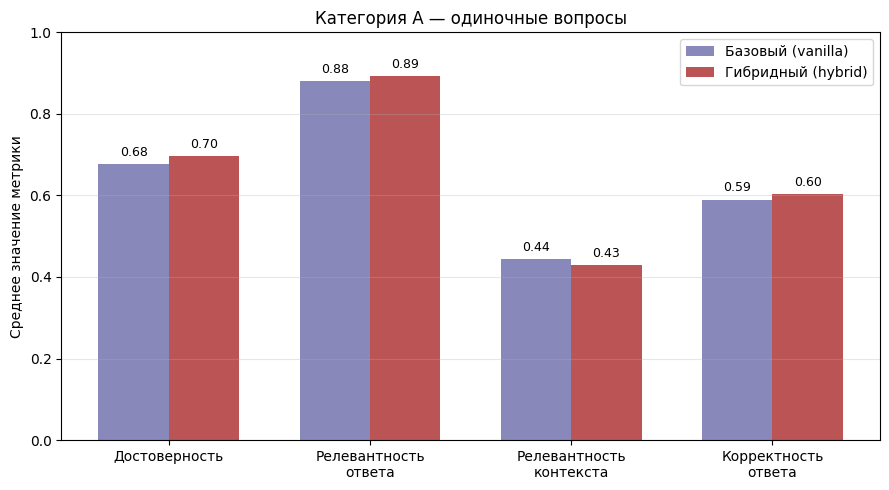

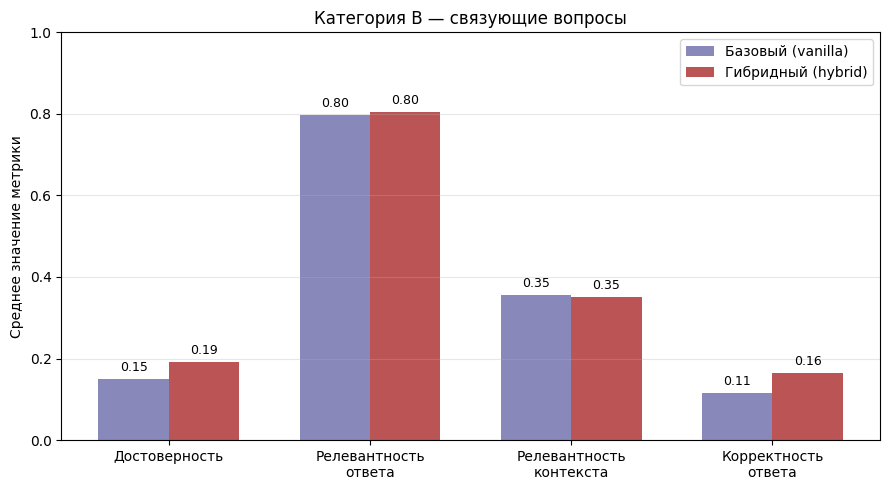

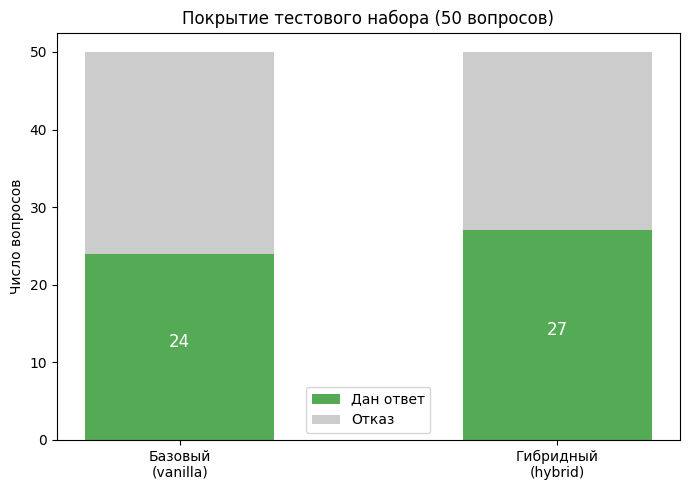

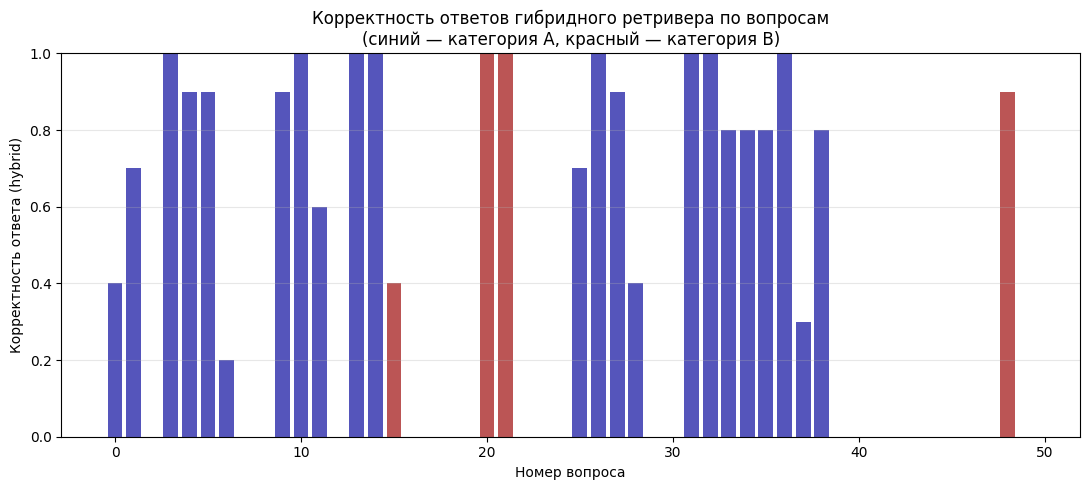

Графики сохранены: chart_metrics_A.png, chart_metrics_B.png,
chart_coverage.png, chart_correctness_dist.png


In [ ]:
# таблицы и графики для главы 3
# прогон делать не надо

import json
import matplotlib.pyplot as plt
import numpy as np

# пути мб на локалке поменять
EVAL_PATH = "/content/drive/MyDrive/vkr/data/eval_results.json"
JUDGE_PATH = "/content/drive/MyDrive/vkr/data/judge_scores.json"

with open(EVAL_PATH, encoding="utf-8") as f:
    er = json.load(f)
with open(JUDGE_PATH, encoding="utf-8") as f:
    js = json.load(f)

metrics = ["faithfulness", "answer_relevancy", "context_relevance", "answer_correctness"]
metric_ru = ["Достоверность", "Релевантность\nответа",
             "Релевантность\nконтекста", "Корректность\nответа"]

def avg(mode, metric, cat=None):
    vals = [r[metric] for r in js[mode]["per_question"]
            if (cat is None or r["category"] == cat) and r[metric] is not None]
    return sum(vals) / len(vals) if vals else 0.0

# ТАБЛИЦА 1: полная таблица метрик (текстом)
print("ТАБЛИЦА 1 — Метрики качества vanilla vs hybrid\n")
for scope, cat in [("Все 50", None), ("Категория A", "A"), ("Категория B", "B")]:
    print(f"  {scope}")
    print(f"  {'Метрика':<22}{'Vanilla':>10}{'Hybrid':>10}{'Δ':>9}")
    for m in metrics:
        v, h = avg("vanilla", m, cat), avg("hybrid", m, cat)
        print(f"  {m:<22}{v:>10.3f}{h:>10.3f}{h-v:>+9.3f}")
    print()

# 2 и 3 столбчатые диаграммы по категориям A и B
for cat, title in [("A", "Категория A — одиночные вопросы"),
                    ("B", "Категория B — связующие вопросы")]:
    v_vals = [avg("vanilla", m, cat) for m in metrics]
    h_vals = [avg("hybrid", m, cat) for m in metrics]
    x = np.arange(len(metrics))
    w = 0.35
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(x - w/2, v_vals, w, label="Базовый (vanilla)", color="#8888bb")
    ax.bar(x + w/2, h_vals, w, label="Гибридный (hybrid)", color="#bb5555")
    ax.set_xticks(x)
    ax.set_xticklabels(metric_ru)
    ax.set_ylabel("Среднее значение метрики")
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    for i, (vv, hh) in enumerate(zip(v_vals, h_vals)):
        ax.text(i - w/2, vv + 0.02, f"{vv:.2f}", ha="center", fontsize=9)
        ax.text(i + w/2, hh + 0.02, f"{hh:.2f}", ha="center", fontsize=9)
    plt.tight_layout()
    plt.savefig(f"chart_metrics_{cat}.png", dpi=150)
    plt.show()

# 4 покрытие (ответил / отказался)
def refused(a):
    return "could not find" in a.lower()
v_ans = sum(1 for r in er if not refused(r["vanilla_answer"]))
h_ans = sum(1 for r in er if not refused(r["hybrid_answer"]))
total = len(er)

fig, ax = plt.subplots(figsize=(7, 5))
labels = ["Базовый\n(vanilla)", "Гибридный\n(hybrid)"]
answered = [v_ans, h_ans]
refused_n = [total - v_ans, total - h_ans]
x = np.arange(2)
ax.bar(x, answered, 0.5, label="Дан ответ", color="#55aa55")
ax.bar(x, refused_n, 0.5, bottom=answered, label="Отказ", color="#cccccc")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Число вопросов")
ax.set_title(f"Покрытие тестового набора ({total} вопросов)")
ax.legend()
for i, a in enumerate(answered):
    ax.text(i, a/2, str(a), ha="center", fontsize=12, color="white")
plt.tight_layout()
plt.savefig("chart_coverage.png", dpi=150)
plt.show()

# 5 распределение answer_correctness по вопросам
fig, ax = plt.subplots(figsize=(11, 5))
idx = np.arange(len(er))
h_corr = [js["hybrid"]["per_question"][i]["answer_correctness"] or 0
          for i in idx]
colors = ["#5555bb" if er[i]["category"] == "A" else "#bb5555" for i in idx]
ax.bar(idx, h_corr, color=colors)
ax.set_xlabel("Номер вопроса")
ax.set_ylabel("Корректность ответа (hybrid)")
ax.set_title("Корректность ответов гибридного ретривера по вопросам\n"
             "(синий — категория A, красный — категория B)")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("chart_correctness_dist.png", dpi=150)
plt.show()

print("Графики сохранены: chart_metrics_A.png, chart_metrics_B.png,")
print("chart_coverage.png, chart_correctness_dist.png")

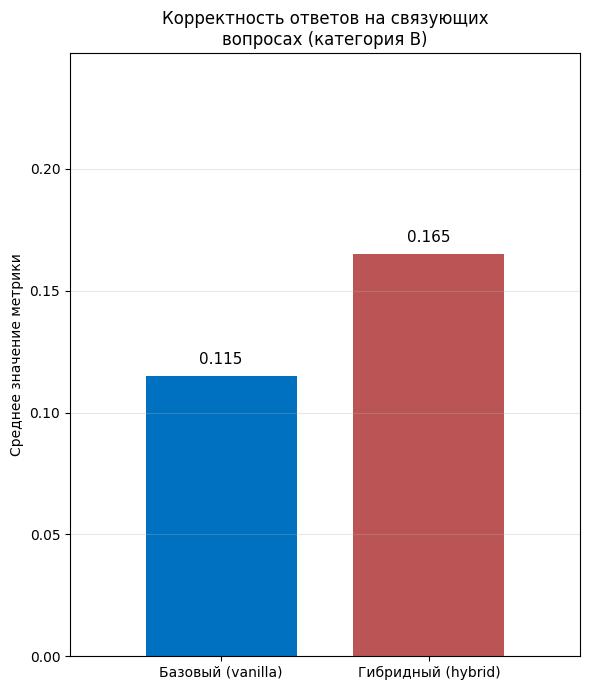

Vanilla: 0.115
Hybrid:  0.165
Δ:       +0.050

График сохранён в /content/drive/MyDrive/vkr/data/chart_correctness_B.png


In [ ]:
# ============================================================
# Столбчатая диаграмма: answer_correctness на категории B
# ============================================================
import json
import matplotlib.pyplot as plt
import numpy as np

JUDGE_PATH = DATA_DIR / "judge_scores.json"
OUT_PATH = DATA_DIR / "chart_correctness_B.png"

with open(JUDGE_PATH, encoding="utf-8") as f:
    js = json.load(f)


def avg_B(mode):
    vals = [r["answer_correctness"] for r in js[mode]["per_question"]
            if r["category"] == "B" and r["answer_correctness"] is not None]
    return sum(vals) / len(vals) if vals else 0.0


v_val = avg_B("vanilla")
h_val = avg_B("hybrid")

# Сдвигаем столбцы ближе друг к другу
x = np.array([0.0, 0.55])
w = 0.4
labels = ["Базовый (vanilla)", "Гибридный (hybrid)"]
values = [v_val, h_val]
colors = ["#0070C0", "#bb5555"]

# Более вытянутый формат
fig, ax = plt.subplots(figsize=(6, 7))
ax.bar(x, values, w, color=colors)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlim(-0.4, 0.95)
ax.set_ylabel("Среднее значение метрики")
ax.set_title("Корректность ответов на связующих\nвопросах (категория B)")

# Зум по Y: с запасом над максимальным значением
y_max = max(values) * 1.5
ax.set_ylim(0, y_max)
ax.grid(axis="y", alpha=0.3)

for i, val in enumerate(values):
    ax.text(x[i], val + y_max * 0.02, f"{val:.3f}", ha="center", fontsize=11)

plt.tight_layout()
plt.savefig(OUT_PATH, dpi=150)
plt.show()

print(f"Vanilla: {v_val:.3f}")
print(f"Hybrid:  {h_val:.3f}")
print(f"Δ:       {h_val - v_val:+.3f}")
print(f"\nГрафик сохранён в {OUT_PATH}")

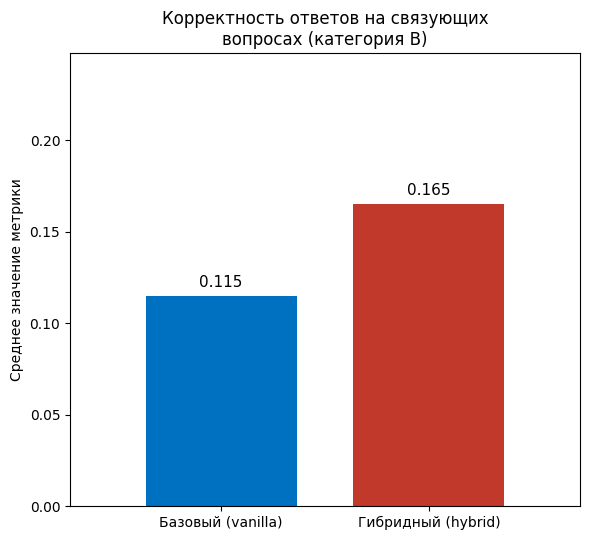

Vanilla: 0.115
Hybrid:  0.165
Δ:       +0.050

График сохранён в /content/drive/MyDrive/vkr/data/chart_correctness_B.png


In [ ]:
# ============================================================
# Столбчатая диаграмма: answer_correctness на категории B
# ============================================================
import json
import matplotlib.pyplot as plt
import numpy as np

JUDGE_PATH = DATA_DIR / "judge_scores.json"
OUT_PATH = DATA_DIR / "chart_correctness_B.png"

with open(JUDGE_PATH, encoding="utf-8") as f:
    js = json.load(f)


def avg_B(mode):
    vals = [r["answer_correctness"] for r in js[mode]["per_question"]
            if r["category"] == "B" and r["answer_correctness"] is not None]
    return sum(vals) / len(vals) if vals else 0.0


v_val = avg_B("vanilla")
h_val = avg_B("hybrid")

x = np.array([0.0, 0.55])
w = 0.4
labels = ["Базовый (vanilla)", "Гибридный (hybrid)"]
values = [v_val, h_val]
colors = ["#0070C0", "#C0392B"]

# Чуть ниже, чем было
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.bar(x, values, w, color=colors)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlim(-0.4, 0.95)
ax.set_ylabel("Среднее значение метрики")
ax.set_title("Корректность ответов на связующих\nвопросах (категория B)")

y_max = max(values) * 1.5
ax.set_ylim(0, y_max)
# Сетка отключена

for i, val in enumerate(values):
    ax.text(x[i], val + y_max * 0.02, f"{val:.3f}", ha="center", fontsize=11)

plt.tight_layout()
plt.savefig(OUT_PATH, dpi=150)
plt.show()

print(f"Vanilla: {v_val:.3f}")
print(f"Hybrid:  {h_val:.3f}")
print(f"Δ:       {h_val - v_val:+.3f}")
print(f"\nГрафик сохранён в {OUT_PATH}")